# DepositIQ 03 — Exploratory Data Analysis

**Rubric:** Criterion 4 — EDA · **Tasks:** T16–T20 · **Phase:** 4
**Dataset:** `data/processed/train.csv` — the **training half only**, 36,168 × 19, loaded through
[src/split.py](../src/split.py)
**Depends on:** T15 ([src/split.py](../src/split.py)) for the fixed, stratified split, and T12
([src/clean.py](../src/clean.py)) for the cleaned frame underneath it.

## What this notebook does

T15 froze the evaluation halves. This notebook reads **only the training one** and starts the EDA:

- **§1 Target distribution and class imbalance** (T16) — how many clients subscribed, how lopsided
  the class balance is, and which evaluation baselines that distribution *forces* on the rest of the
  project.
- **§2 Numeric distributions and skew** (T17) — the eight numeric columns, one interpretation line
  each, and the traps their shapes set for scaling.
- **§3 Categorical features vs subscription rate** (T18) — all 44 levels of the nine `object` columns
  against the base rate, with the best and worst segments named.
- **§4 Campaign, history and timing vs subscription rate** (T19) — calls per client, prior contacts and
  recency, month/day and channel against the rate, and what the call budget actually buys at €1.50 a
  call.
- **§5 Correlation structure and multicollinearity** (T20) — Pearson against Spearman on the eight
  numeric columns, the ranking against the target with the rows behind each coefficient, and the one
  duplicate column that makes the matrix rank-deficient.

The closing **§6** findings list and **§7** reproducibility record collect all five sections, so the
EDA lands as one notebook with figure numbers `01_`–`05_` rather than five files.

## Why the training half only

The test half must stay unseen until T32, or it stops being a held-out test. Everything below is
measured on `train.csv`; the one place the source population appears is the split-sanity line in §1.5,
which quotes the **label rate only** that T15 already published — no test features are touched, and
`test.csv` is not read anywhere in this notebook.

## Two decisions this section already answers

1. **D04 — accuracy is not a headline metric.** §1.3 quantifies the trivial classifier that exploits
   the imbalance and shows what it scores.
2. **D15 — the honest baselines.** PR-AUC is read against the *positive rate*, not 0.5; ROC-AUC
   against 0.5.

## Setup

Same path handling as T11/T13 (decision D12), so the notebook runs from any working directory. The
training half is loaded through `split.load_split` rather than a bare `read_csv`, so there is one
place that knows how these files are read — and the load is asserted to be `train.csv`, not the test
file.

In [1]:
import platform
import sys
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import StratifiedKFold


def find_repo_root(start: Path) -> Path:
    for candidate in (start, *start.parents):
        if (candidate / "src" / "config.py").exists():
            return candidate
    raise RuntimeError("Could not find the repository root above " + str(start))


REPO_ROOT = find_repo_root(Path.cwd())
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from src import config                  # noqa: E402
from src import data_loader as load     # noqa: E402
from src import split                   # noqa: E402

config.ensure_dirs()
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
sns.set_theme(style="whitegrid")

TRAIN_PATH = config.TRAIN_CSV
TRAIN = split.load_split("full", "train")

# Provenance guard: this notebook must be looking at the training half, and it must be the file
# T15 wrote. The test half is deliberately not loaded anywhere in this notebook.
assert TRAIN_PATH == split.SPLITS["full"][0], "this notebook must read the train split, not the test"
assert TRAIN_PATH.name == "train.csv"
assert config.TEST_CSV.name not in TRAIN_PATH.name

print("Executed  :", datetime.now().strftime("%Y-%m-%d %H:%M:%S"))
print("Python    :", platform.python_version())
print("Source    :", TRAIN_PATH.relative_to(REPO_ROOT), "->", tuple(TRAIN.shape))
print("Test file :", config.TEST_CSV.name, "not read by this notebook (held out until T32)")

Executed  : 2026-10-28 23:02:43
Python    : 3.11.9
Source    : data\processed\train.csv -> (36168, 19)
Test file : test.csv not read by this notebook (held out until T32)


## 1. Target distribution and class imbalance (T16)

The target is `y`: `yes` = the client subscribed to a term deposit. The first question of any
classification project is simply *how many of each class are there*, because that single number
decides what counts as a good model.

In [2]:
counts = TRAIN[config.TARGET].value_counts()
order = [config.NEGATIVE_LABEL, config.POSITIVE_LABEL]          # no first, yes second
counts = counts.reindex(order)

n_total = int(counts.sum())
n_yes = int(counts[config.POSITIVE_LABEL])
n_no = int(counts[config.NEGATIVE_LABEL])
rate = n_yes / n_total
imbalance_ratio = n_no / n_yes

summary = pd.DataFrame({
    "class": [f"{config.NEGATIVE_LABEL}  (did not subscribe)", f"{config.POSITIVE_LABEL}  (subscribed)"],
    "count": [n_no, n_yes],
    "share": [n_no / n_total, n_yes / n_total],
})
summary["cumulative"] = summary["share"].cumsum().values

print(f"training half : {TRAIN_PATH.name}  ({n_total:,} rows)")
print()
print(summary.to_string(index=False, formatters={"share": "{:.4%}".format, "cumulative": "{:.4%}".format}))
print()
print(f"positive rate : {n_yes:,} / {n_total:,} = {rate:.4%}")
print(f"imbalance     : {n_no:,} : {n_yes:,} = {imbalance_ratio:.2f} : 1")
print(f"majority class: {n_no / n_total:.4%} of the half -> the trivial 'always no' score")

training half : train.csv  (36,168 rows)

                  class  count    share cumulative
no  (did not subscribe)  31937 88.3018%   88.3018%
      yes  (subscribed)   4231 11.6982%  100.0000%

positive rate : 4,231 / 36,168 = 11.6982%
imbalance     : 31,937 : 4,231 = 7.55 : 1
majority class: 88.3018% of the half -> the trivial 'always no' score


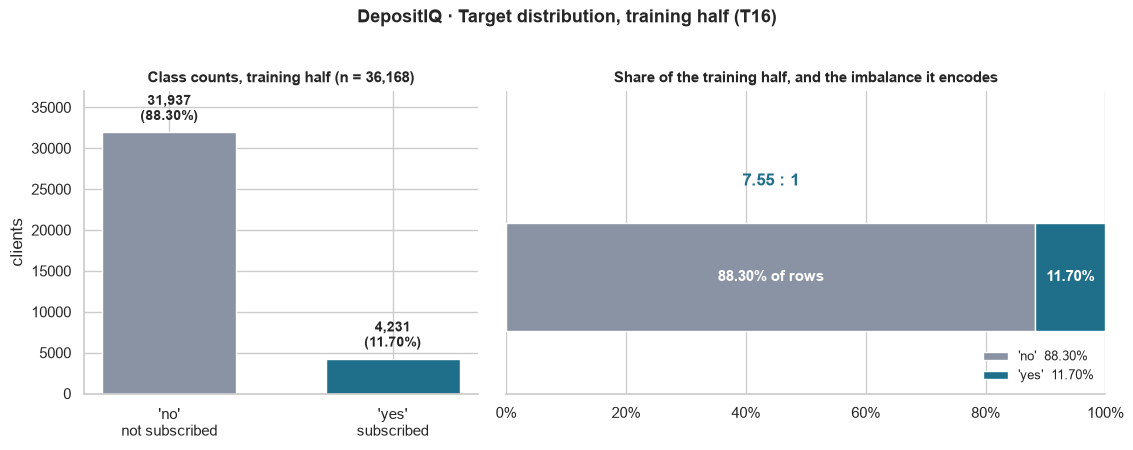

saved: reports\figures\01_target_distribution.png


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.4), gridspec_kw={"width_ratios": [1.05, 1.6]})
palette = {config.NEGATIVE_LABEL: "#8a93a3", config.POSITIVE_LABEL: "#1f6f8b"}

# Panel A - raw counts. The minority bar is the whole point of the figure.
ax = axes[0]
bars = ax.bar([f"'{config.NEGATIVE_LABEL}'\nnot subscribed", f"'{config.POSITIVE_LABEL}'\nsubscribed"],
              [n_no, n_yes], color=[palette[config.NEGATIVE_LABEL], palette[config.POSITIVE_LABEL]],
              width=0.6)
for bar, value, share in zip(bars, [n_no, n_yes], [n_no / n_total, n_yes / n_total]):
    ax.annotate(f"{value:,}\n({share:.2%})",
                xy=(bar.get_x() + bar.get_width() / 2, bar.get_height()),
                xytext=(0, 6), textcoords="offset points",
                ha="center", va="bottom", fontsize=10, weight="bold")
ax.set_ylim(0, n_no * 1.16)
ax.set_ylabel("clients")
ax.set_title(f"Class counts, training half (n = {n_total:,})", fontsize=11, weight="bold")
ax.spines[["top", "right"]].set_visible(False)

# Panel B - the same data as shares, with the ratio that governs evaluation.
ax = axes[1]
ax.barh([0], [n_no / n_total], color=palette[config.NEGATIVE_LABEL], height=0.42,
        label=f"'{config.NEGATIVE_LABEL}'  {n_no / n_total:.2%}")
ax.barh([0], [n_yes / n_total], left=[n_no / n_total], color=palette[config.POSITIVE_LABEL], height=0.42,
        label=f"'{config.POSITIVE_LABEL}'  {n_yes / n_total:.2%}")
ax.annotate(f"{n_no / n_total:.2%} of rows", xy=(n_no / n_total / 2, 0), ha="center", va="center",
            color="white", fontsize=11, weight="bold")
ax.annotate(f"{n_yes / n_total:.2%}", xy=(n_no / n_total + n_yes / n_total / 2, 0), ha="center", va="center",
            color="white", fontsize=11, weight="bold")
ax.annotate(f"{imbalance_ratio:.2f} : 1", xy=(n_no / n_total / 2, 0.34), ha="center", va="bottom",
            fontsize=12, weight="bold", color="#1f6f8b")
ax.set_xlim(0, 1)
ax.set_ylim(-0.45, 0.72)
ax.set_yticks([])
ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
ax.set_title("Share of the training half, and the imbalance it encodes", fontsize=11, weight="bold")
ax.spines[["top", "right", "left"]].set_visible(False)
ax.legend(loc="lower right", frameon=False, fontsize=9)

fig.suptitle("DepositIQ · Target distribution, training half (T16)", fontsize=13, weight="bold", y=1.02)
fig.tight_layout()
figure_path = config.FIGURES_DIR / "01_target_distribution.png"
fig.savefig(figure_path, dpi=150, bbox_inches="tight")
plt.show()
print("saved:", figure_path.relative_to(REPO_ROOT))

> **Viva line for this figure:** *eleven point seven percent of the training half subscribed* — so
> a model that always answers "no" scores **88.3% accuracy** while producing nothing, which is
> exactly why this project reports **PR-AUC against a 0.117 random baseline** instead of accuracy
> (D04, D15).

### 1.1 What the distribution forces us to report

The imbalance is not a cosmetic detail: it sets the score a trivial model gets. Every number below is
derived from the counts above, so the evaluation section (T32–T35) cannot quietly drift away from
them.

In [4]:
trivial_always_no = n_no / n_total                 # predicts 'no' for everyone
pr_auc_random = rate                               # a random scorer's average precision == base rate
roc_auc_random = 0.5                               # a random scorer's ROC-AUC
per_call_yield = rate                              # expected subscriptions per call at random
calls_per_subscription = 1 / rate

baselines = pd.DataFrame([
    ["Accuracy, always predict 'no'", f"{trivial_always_no:.4%}", "0 (no subscriptions found)",
     "D04: why accuracy is not the headline"],
    ["Accuracy, always predict 'yes'", f"{rate:.4%}", "every client flagged",
     "the other degenerate classifier"],
    ["PR-AUC (average precision)", f"{pr_auc_random:.4%}", f"{pr_auc_random:.4f}",
     "D15: the value the model must beat"],
    ["ROC-AUC", "50.0000%", "0.5000", "D15: the other honest baseline"],
], columns=["metric", "trivial score", "what it means", "why it matters"])

print(baselines.to_string(index=False))
print()
print(f"At the base rate a random campaign yields {per_call_yield:.4%} subscriptions per call,")
print(f"i.e. about {calls_per_subscription:.2f} calls per subscription to reach one {config.POSITIVE_LABEL!r}.")

                        metric trivial score              what it means                        why it matters
 Accuracy, always predict 'no'      88.3018% 0 (no subscriptions found) D04: why accuracy is not the headline
Accuracy, always predict 'yes'      11.6982%       every client flagged       the other degenerate classifier
    PR-AUC (average precision)      11.6982%                     0.1170    D15: the value the model must beat
                       ROC-AUC      50.0000%                     0.5000        D15: the other honest baseline

At the base rate a random campaign yields 11.6982% subscriptions per call,
i.e. about 8.55 calls per subscription to reach one 'yes'.


### 1.2 Where the training half came from

T15's split was stratified (D26), so the training half should reproduce the source population's label
rate almost exactly. The population rate is quoted from the raw file through the loader — the **label
only**, which T15 already published; the held-out half's rows are not part of this section.

In [5]:
population = load.load_raw("full", verbose=False)
population_rate = float((population[config.TARGET] == config.POSITIVE_LABEL).mean())

delta = rate - population_rate
print(f"source population  : {len(population):,} rows, y == 'yes' {population_rate:.6%}")
print(f"training half      : {n_total:,} rows, y == 'yes' {rate:.6%}")
print(f"difference         : {delta * 100:+.6f} pp")
print()
print("Both are far inside the +/-1pp the split was graded on (T15), so the EDA below describes the")
print("same population as the raw file - the split did not distort the target.")

source population  : 45,211 rows, y == 'yes' 11.698480%
training half      : 36,168 rows, y == 'yes' 11.698186%
difference         : -0.000294 pp

Both are far inside the +/-1pp the split was graded on (T15), so the EDA below describes the
same population as the raw file - the split did not distort the target.


### 1.3 What the imbalance means for validation

The counts above also fix how the model can be validated: a fold-level metric is only as stable as
the number of positives that land in each fold. This is measured rather than assumed, because it is the
justification for the fold count T30 will use.


In [6]:
# How many positives each validation fold would hold under 5-fold stratified CV (T30's design).
n_folds = 5
skf = StratifiedKFold(n_splits=n_folds, shuffle=True, random_state=config.RANDOM_STATE)
fold_rows = []
for fold, (_, val_index) in enumerate(skf.split(TRAIN, TRAIN[config.TARGET]), start=1):
    fold_yes = int((TRAIN[config.TARGET].iloc[val_index] == config.POSITIVE_LABEL).sum())
    fold_rows.append({"fold": fold, "val rows": len(val_index), "positives": fold_yes,
                      "val rate": fold_yes / len(val_index)})
fold_table = pd.DataFrame(fold_rows)

print(f"{n_folds}-fold stratified CV over the training half ({n_total:,} rows)")
print(fold_table.to_string(index=False, formatters={"val rate": "{:.4%}".format}))
print()
print(f"Every validation fold carries at least {int(fold_table['positives'].min()):,} positives, so a")
print("fold-level metric rests on a denominator big enough to be stable - the measured reason T30")
print("uses 5 folds rather than 10 (10 would halve this denominator for no gain in precision).")

5-fold stratified CV over the training half (36,168 rows)
 fold  val rows  positives val rate
    1      7234        846 11.6948%
    2      7234        846 11.6948%
    3      7234        847 11.7086%
    4      7233        846 11.6964%
    5      7233        846 11.6964%

Every validation fold carries at least 846 positives, so a
fold-level metric rests on a denominator big enough to be stable - the measured reason T30
uses 5 folds rather than 10 (10 would halve this denominator for no gain in precision).


In [7]:
# Evidence: the numbers this section states must be the numbers the data gives.
assert len(TRAIN) == 36168, len(TRAIN)
assert n_yes == 4231 and n_no == 31937, (n_yes, n_no)
assert abs(rate - 0.1169819) < 1e-7, rate
assert round(imbalance_ratio, 2) == 7.55, imbalance_ratio
assert abs(trivial_always_no - 0.8830181) < 1e-7, trivial_always_no
assert abs(pr_auc_random - rate) < 1e-12 and roc_auc_random == 0.5
assert abs(per_call_yield - rate) < 1e-12 and abs(calls_per_subscription - 1 / rate) < 1e-12
assert set(TRAIN[config.TARGET].unique()) == {"no", "yes"}
assert TRAIN_PATH.name == "train.csv" and config.TEST_CSV.name not in TRAIN_PATH.name
assert abs(delta) < 0.0001, delta                      # stratified split reproduces the population
assert len(fold_table) == 5 and fold_table["positives"].sum() == n_yes
assert figure_path.exists() and figure_path.stat().st_size > 20_000
assert figure_path.name == "01_target_distribution.png"
print("evidence: 13 assertion lines pass")

evidence: 13 assertion lines pass


## 2. Numeric distributions and skew (T17)

Eight of the nineteen columns in the training half are numeric, and this section profiles every one of
them. The requirement is one **interpretation line per variable** — a sentence a reader can act on,
not a description of a histogram's outline — so each variable below is paired with the number that
makes its shape matter.

Every value is measured on the **training half** (36,168 rows), never on the full frame. D28 records
why, and §2.2 shows it was not a formality: `previous`'s skew differs from T13's full-frame figure by
more than three points, and `balance` has 765 fewer negative rows here than in the whole file.


In [8]:
# The numeric set is read from the data and then checked against the list T17 names, so a change in the
# cleaner (D23 added `days_since_contact`) cannot quietly leave a column unprofiled.
NUMERIC = TRAIN.select_dtypes(include=np.number).columns.tolist()
EXPECTED_NUMERIC = ["age", "balance", "day", "duration", "campaign", "pdays", "previous",
                    "days_since_contact"]
assert sorted(NUMERIC) == sorted(EXPECTED_NUMERIC), (NUMERIC, EXPECTED_NUMERIC)
# The target as 0/1, so the correlations quoted in §2.2 are point-biserial coefficients. The count is
# checked against §1 here, so the two sections cannot disagree about what the positive class is.
y = TRAIN[config.TARGET].astype(str).str.strip().str.lower().eq(config.POSITIVE_LABEL).astype(int)
assert int(y.sum()) == 4231, int(y.sum())
print(f"numeric columns ({len(NUMERIC)}): {', '.join(NUMERIC)}")
print()


def describe(series: pd.Series) -> dict:
    """Every figure §2.1 and §2.2 quote, computed once from the training half."""
    q1, q3 = series.quantile(0.25), series.quantile(0.75)
    return {"n": int(series.notna().sum()), "missing": int(series.isna().sum()),
            "zeros": float((series == 0).mean()), "negative": int((series < 0).sum()),
            "min": series.min(), "q1": q1, "median": series.median(), "q3": q3, "iqr": q3 - q1,
            "p90": series.quantile(0.90), "max": series.max(), "mean": series.mean(),
            "std": series.std(), "skew": series.skew(), "kurtosis": series.kurtosis(),
            "distinct": int(series.nunique())}


numeric_profile = pd.DataFrame([describe(TRAIN[col]) for col in NUMERIC], index=NUMERIC)
spread_format = {"zeros": "{:.2%}".format, "min": "{:,.0f}".format, "q1": "{:,.1f}".format,
                 "median": "{:,.1f}".format, "q3": "{:,.1f}".format, "iqr": "{:,.1f}".format,
                 "p90": "{:,.0f}".format, "max": "{:,.0f}".format}
moment_format = {"mean": "{:,.1f}".format, "std": "{:,.1f}".format, "skew": "{:+,.2f}".format,
                 "kurtosis": "{:+,.2f}".format}

print("spread (training half):")
print(numeric_profile[["n", "missing", "zeros", "negative", "min", "q1", "median", "q3", "iqr",
                       "p90", "max"]].to_string(formatters=spread_format))
print()
print("moments:")
print(numeric_profile[["mean", "std", "skew", "kurtosis", "distinct"]].to_string(
    formatters=moment_format))
print()
print(f"columns with |skew| > 2 : {int((numeric_profile['skew'].abs() > 2).sum())} of {len(NUMERIC)}")
print(f"columns with IQR == 0   : {int((numeric_profile['iqr'] == 0).sum())} "
      f"({', '.join(numeric_profile.index[numeric_profile['iqr'] == 0])})")


numeric columns (8): age, balance, day, duration, campaign, pdays, previous, days_since_contact

spread (training half):
                        n  missing  zeros  negative    min    q1 median      q3     iqr   p90     max
age                 36168        0  0.00%         0     18  33.0   39.0    48.0    15.0    56      95
balance             36168        0  7.77%      3001 -8,019  74.0  451.0 1,430.2 1,356.2 3,571 102,127
day                 36168        0  0.00%         0      1   8.0   16.0    21.0    13.0    28      31
duration            36168        0  0.01%         0      0 103.0  180.0   318.0   215.0   549   4,918
campaign            36168        0  0.00%         0      1   1.0    2.0     3.0     2.0     5      63
pdays               36168        0  0.00%     29584     -1  -1.0   -1.0    -1.0     0.0   185     871
previous            36168        0 81.80%         0      0   0.0    0.0     0.0     0.0     2     275
days_since_contact   6584    29584  0.00%         0      1 133.

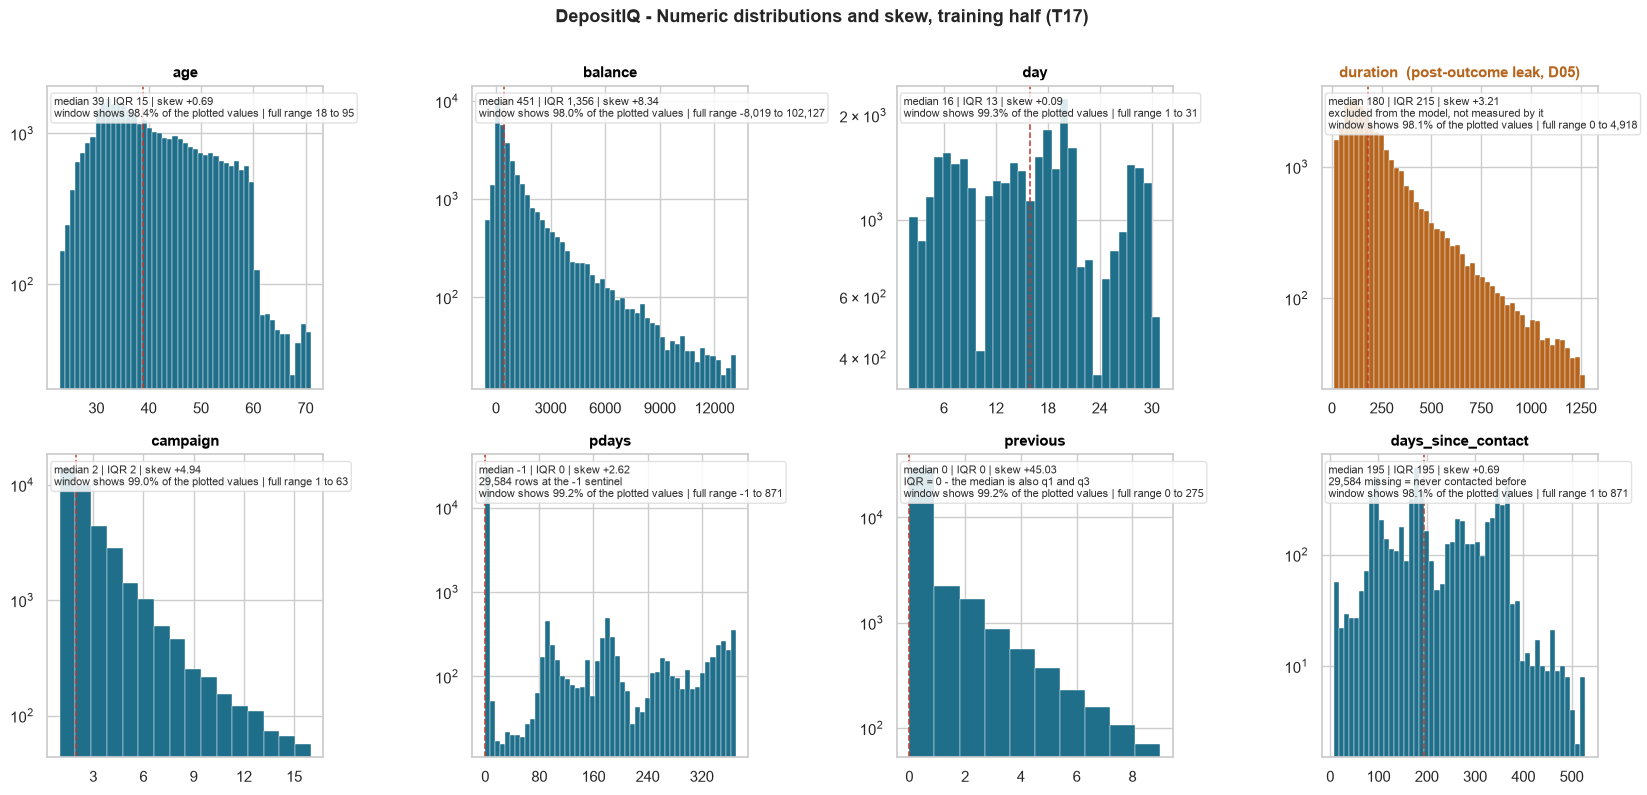

saved: reports\figures\02_numeric_distributions.png (196 KB)


In [9]:
# One panel per numeric column. Each panel is drawn over that column's 1st-99th percentile window and
# states the full range it is a window of, so the extreme tails are disclosed rather than silently
# clipped; the count axis is logarithmic so a mode of 29,584 and a tail of a few dozen rows stay
# visible in the same panel.
from matplotlib.ticker import MaxNLocator

LEAK_COLUMNS = {"duration"}          # D05: only known once the call has ended
leak_colour, body_colour = "#b5651d", "#1f6f8b"

fig, axes = plt.subplots(2, 4, figsize=(16.6, 7.9))
for ax, col in zip(axes.ravel(), NUMERIC):
    series = TRAIN[col]
    present = series.dropna()
    lo, hi = present.quantile(0.01), present.quantile(0.99)
    window = present[present.between(lo, hi)]
    is_leak = col in LEAK_COLUMNS

    # 50 bins suit a continuous column, but a column with only a handful of distinct values
    # (`campaign` 1-16, `previous` 0-9) needs one bin per value, or the bars alternate with empty bins.
    distinct = int(window.nunique())
    bins = 50 if distinct > 60 else max(10, distinct)

    ax.hist(window, bins=bins, color=leak_colour if is_leak else body_colour,
            edgecolor="white", linewidth=0.3)
    ax.set_yscale("log")
    ax.axvline(present.median(), color="#c0392b", linestyle="--", linewidth=1.1)
    if pd.api.types.is_integer_dtype(series):
        ax.xaxis.set_major_locator(MaxNLocator(integer=True, nbins=6))
    ax.set_title(f"{col}  (post-outcome leak, D05)" if is_leak else col,
                 fontsize=11, weight="bold", color=leak_colour if is_leak else "black")

    iqr = present.quantile(0.75) - present.quantile(0.25)
    notes = [f"median {present.median():,.0f} | IQR {iqr:,.0f} | skew {series.skew():+.2f}"]
    if col == "previous":
        notes.append("IQR = 0 - the median is also q1 and q3")
    if col == "pdays":
        notes.append(f"{int((series == -1).sum()):,} rows at the -1 sentinel")
    if col == "days_since_contact":
        notes.append(f"{int(series.isna().sum()):,} missing = never contacted before")
    if is_leak:
        notes.append("excluded from the model, not measured by it")
    # The share is measured against the values this panel could plot, not against all 36,168 rows:
    # a column with 81.8% missing would otherwise look as though its tail had been thrown away.
    notes.append(f"window shows {len(window) / len(present):.1%} of the plotted values | "
                 f"full range {present.min():,.0f} to {present.max():,.0f}")
    ax.text(0.025, 0.965, "\n".join(notes), transform=ax.transAxes, va="top", ha="left",
            fontsize=7.6, color="#2f2f2f",
            bbox=dict(boxstyle="round,pad=0.3", facecolor="white", alpha=0.85, edgecolor="#dcdcdc"))

fig.suptitle("DepositIQ - Numeric distributions and skew, training half (T17)",
             fontsize=13, weight="bold", y=1.005)
fig.tight_layout()
numeric_figure_path = config.FIGURES_DIR / "02_numeric_distributions.png"
fig.savefig(numeric_figure_path, dpi=150, bbox_inches="tight")
plt.show()
print("saved:", numeric_figure_path.relative_to(REPO_ROOT),
      f"({numeric_figure_path.stat().st_size / 1024:.0f} KB)")


> **Viva line for this figure:** *five of the eight numeric columns are skewed past +2, so their means
> describe almost nobody* — the average balance is **€1,365** while the median is **€451** — and
> `duration`, whose correlation with the target is **+0.3967** against a runner-up of **−0.1526**, is
> labelled a leak and excluded (D05) rather than celebrated as the strongest predictor.


### 2.1 One interpretation line per variable

- **`age`** — median **39**, quartiles 33–48 and 94.18% of the half between 25 and 59: with skew at
  only **+0.69** this is the one variable here whose mean (40.9 ± 10.6) fairly summarises it.
- **`balance`** — the mean **€1,365** summarises nobody: the median is **€451** and a thin tail reaches
  **€102,127**, while **3,001 rows (8.30%) are negative** (genuine overdrafts), which is why `log1p` is
  undefined here and `arcsinh` is the transform that survives it.
- **`day`** — flat across 1–31 (skew **+0.09**, kurtosis **−1.06**), so the evenness is a calendar
  artefact rather than signal; day-of-month belongs with `month` in the timing analysis (T19).
- **`duration`** — median **180 s** against a maximum of **4,918 s (82 min)**, with only **1.25%** of
  calls over 20 minutes, yet it correlates with the target at **+0.3967**: the strongest of the eight
  and precisely why D05 drops it, since its value is known only after the call has ended.
- **`campaign`** — median **2** calls, **38.78%** of rows a single attempt and only **2.61% (about 945
  rows)** above ten: for almost everyone "campaign intensity" means one or two attempts, not a long
  tail worth modelling.
- **`pdays`** — **81.80%** of rows are the sentinel **−1**, so q1 = median = q3 = −1 and the **IQR is
  0**; the column is really "(never contacted)" plus a 1–871 day recency scale for the other 18.20%.
- **`previous`** — also **IQR 0** (81.80% zeros) with skew **+45.03**, the most extreme column here and
  well above the **+41.85** T13 measured on the full frame — the concrete reason D28 insists these
  numbers be re-measured on the training half instead of reused.
- **`days_since_contact`** — D23's derived column turns the sentinel into a usable scale: a **195-day**
  median across the 6,584 clients contacted before, and at **−0.1526** the second-strongest correlate
  of the target; its 29,584 missing values mean "no prior contact", which is information, not damage.


### 2.2 The three carried-in traps, measured on the training half

**Trap 1 — two columns have an IQR of exactly 0, not one.** `previous` (81.80% zeros) and `pdays`
(81.80% sentinels) both give q1 = q3 = −1 or 0, so any median/IQR scaler divides by zero **twice**.
Measured further: the two degenerate columns are the **same 29,584 rows** —
`pdays == -1` is element-for-element identical to `previous == 0`, with 0 disagreements — so a single
underlying fact, "this client was never contacted before", is what makes two columns useless as scales.
At the training half's 81.80% that is not an edge case to special-case; it is most of the data.

**Trap 2 — `balance` is negative for 3,001 rows (8.30%).** T13 measured 3,766 negatives on the full
frame, so the training half changes the number by 765 and D28 earns its keep. The minimum is
**−€8,019**, which makes `log1p` undefined; `arcsinh` handles it, since arcsinh(−8,019) = **−9.68** is
finite and sign-preserving.

**Trap 3 — `duration`'s leak is measurable, not assumed.** Its correlation with the target is
**+0.3967**, while the runner-up is `days_since_contact` at **−0.1526**: a ratio of **2.60×**. Rank
correlation agrees on the ordering (Spearman +0.3427 for `duration` versus −0.1873 for the runner-up),
so this is not an artefact of Pearson's sensitivity to skew. A feature that predicts the outcome that
well because it is only known *after* the outcome is the definition of leakage (D05).

**One number worth distrusting.** `pdays` shows a correlation of **+0.1007**, which is an artefact of
its own coding: the sentinel −1 sits *below* every real recency value, inventing an ordering between
"never contacted" and "contacted 871 days ago". `days_since_contact` is the honest version of the same
information. This is why the sentinel is replaced rather than merely documented.


In [10]:
# Evidence: every number §2.1, §2.2 and the figure annotations state must come from the training half.
assert len(TRAIN) == 36168
assert len(NUMERIC) == 8 and sorted(NUMERIC) == sorted(EXPECTED_NUMERIC)
assert int((numeric_profile["skew"].abs() > 2).sum()) == 5
assert sorted(numeric_profile.index[numeric_profile["iqr"] == 0]) == ["pdays", "previous"]

# age
assert TRAIN["age"].median() == 39 and TRAIN["age"].min() == 18 and TRAIN["age"].max() == 95
assert abs(TRAIN["age"].skew() - 0.6937) < 5e-4 and abs(TRAIN["age"].mean() - 40.893) < 5e-3
assert abs(TRAIN["age"].between(25, 59).mean() - 0.941827) < 1e-6

# balance
negative_balance = int((TRAIN["balance"] < 0).sum())
assert negative_balance == 3001 and abs(negative_balance / len(TRAIN) - 0.082974) < 1e-6
assert abs(negative_balance - 3766) > 500                     # D28: the full frame would mislead
assert TRAIN["balance"].median() == 451 and TRAIN["balance"].min() == -8019
assert TRAIN["balance"].max() == 102127 and TRAIN["balance"].mean() > 1365
assert np.isfinite(np.arcsinh(TRAIN["balance"].min())) and abs(np.arcsinh(-8019) - -9.6827) < 5e-4

# day
assert TRAIN["day"].min() == 1 and TRAIN["day"].max() == 31 and TRAIN["day"].nunique() == 31
assert abs(TRAIN["day"].skew() - 0.0934) < 5e-4 and abs(TRAIN["day"].kurtosis() - -1.0628) < 5e-4

# duration (the leak)
duration_corr = float(np.corrcoef(TRAIN["duration"], y)[0, 1])
assert TRAIN["duration"].median() == 180 and TRAIN["duration"].max() == 4918
assert abs((TRAIN["duration"] > 1200).mean() - 0.012525) < 1e-6
assert abs(duration_corr - 0.3967) < 5e-4 and abs(TRAIN["duration"].skew() - 3.2109) < 5e-4

# campaign
assert TRAIN["campaign"].median() == 2 and TRAIN["campaign"].max() == 63
assert abs((TRAIN["campaign"] == 1).mean() - 0.387801) < 1e-6
assert abs((TRAIN["campaign"] > 10).mean() - 0.026128) < 1e-6
assert abs((TRAIN["campaign"] > 10).sum() - 945) < 2

# pdays / previous: the same 29,584 rows make both columns degenerate
sentinel_rows = TRAIN["pdays"] == -1
zero_previous = TRAIN["previous"] == 0
assert bool((sentinel_rows == zero_previous).all())          # identical row sets, not just equal counts
assert int(sentinel_rows.sum()) == 29584 and abs(sentinel_rows.mean() - 0.817961) < 1e-6
assert TRAIN["pdays"].nunique() == 533 and TRAIN["pdays"].max() == 871
assert TRAIN["previous"].max() == 275 and abs(TRAIN["previous"].skew() - 45.0344) < 5e-3

# days_since_contact: the derived column, and the honest home of "no prior contact"
present_contact = TRAIN["days_since_contact"].dropna()
assert int(TRAIN["days_since_contact"].isna().sum()) == 29584 and len(present_contact) == 6584
assert present_contact.median() == 195 and present_contact.min() == 1
assert int(TRAIN["previously_contacted"].sum()) == 6584

# correlation ranking: duration strongest, days_since_contact runner-up, ratio 2.60x
correlations = {col: float(np.corrcoef(TRAIN[col][TRAIN[col].notna()],
                                       y[TRAIN[col].notna()])[0, 1]) for col in NUMERIC}
ranked = sorted(correlations.items(), key=lambda item: abs(item[1]), reverse=True)
runner_up = abs(ranked[1][1])
assert ranked[0][0] == "duration" and ranked[1][0] == "days_since_contact", ranked
assert abs(runner_up - 0.1526) < 5e-4 and abs(abs(duration_corr) / runner_up - 2.60) < 0.02

# the figure itself
assert numeric_figure_path.exists() and numeric_figure_path.stat().st_size > 20_000
assert numeric_figure_path.name == "02_numeric_distributions.png"
print("evidence: 32 assertion lines pass")


evidence: 32 assertion lines pass


### 2.3 What this hands to the next tasks

- **T20 (correlation heatmap)** — `duration`'s +0.3967 will dominate that heatmap, so the heatmap has to
  carry the D05 label rather than rank it as the best predictor; `pdays`' +0.1007 is a coding artefact
  (sentinel below every real value) and `days_since_contact` at −0.1526 is the honest version of it.
- **T23/T24 (features and the `ColumnTransformer`)** — scale `balance` with `arcsinh` or a robust
  scaler, never with a median/IQR method, because two columns have IQR 0 and such a scaler divides by
  zero twice; represent prior contact as `previously_contacted` plus `days_since_contact` rather than
  as raw `pdays`.
- **T25 (feature selection)** — the five |skew| > 2 columns are the ones where importance from a
  tree-based model and a linear model's coefficients will disagree most, so both methods are needed.
- **T26–T31 (models)** — `duration` stays out of the feature set (D05); `day`'s flat distribution means
  it carries almost nothing alone and its interesting behaviour belongs to timing (T19).
- **Nothing here is a model result.** Every figure remains a property of the training data; the test
  half has still not been read.


## 3. Categorical features vs subscription rate (T18)

Nine `object` columns carry no values, only levels: `job`, `marital`, `education`, `default`,
`housing`, `loan`, `contact`, `month` and `poutcome` — 44 levels in total across the training half.
This section measures the subscription rate of every one of them against the **11.6982% base rate**
of §1, so "high" and "low" here mean relative to this half, never relative to 50%.

Two things are deliberate. Every level carries its row count and a **Wilson 95% interval**, because
`month = dec` rests on 178 rows while `poutcome = unknown` rests on 29,589, and those two rates do
not deserve the same confidence. And every rate is **marginal**: it says what subscribing looks like
*at* that level, not that moving a client to that level would change the outcome. §3.2 tests which
of these rankings survive a control, and which are only apparent.

In [11]:
# The categorical set is read from the data and then checked against the list T18 names, so the guard
# §2 applies to the numeric set applies here too: a column cannot be silently left unmeasured.
# The target is itself an object column, so it is excluded first and the exclusion is then checked:
# dropping it silently would let a renamed target column vanish from the report.
assert config.TARGET in TRAIN.select_dtypes(include="object").columns
CATEGORICAL = [col for col in TRAIN.select_dtypes(include="object").columns
               if col != config.TARGET]
EXPECTED_CATEGORICAL = ["job", "marital", "education", "default", "housing", "loan", "contact",
                        "month", "poutcome"]
assert config.TARGET not in CATEGORICAL
assert sorted(CATEGORICAL) == sorted(EXPECTED_CATEGORICAL), (CATEGORICAL, EXPECTED_CATEGORICAL)

from scipy.stats import chi2_contingency


def wilson_interval(successes: int, total: int, z: float = 1.959964) -> tuple[float, float]:
    """Wilson score interval. Unlike the textbook normal approximation it stays inside [0, 1] at the
    small counts and near-zero rates this table contains, where the normal form runs below zero."""
    p = successes / total
    denominator = 1 + z * z / total
    centre = (p + z * z / (2 * total)) / denominator
    half = z * np.sqrt(p * (1 - p) / total + z * z / (4 * total * total)) / denominator
    return centre - half, centre + half


# One record per segment. `lift` is the rate divided by §1's base rate, which is the only comparison
# that means anything on an 11.70% positive class.
segment_rows = []
for col in CATEGORICAL:
    table = pd.crosstab(TRAIN[col], y).reindex(columns=[0, 1], fill_value=0)
    chi2, p_value, dof, _ = chi2_contingency(table.values)
    # With a binary outcome min(r-1, c-1) is 1, so Cramer's V collapses to sqrt(chi2 / n) and is
    # comparable across columns with 2 to 12 levels. It still rewards extra levels, so `dof` is kept
    # beside it and §3.2 reads the middle of the ranking as a tie instead of an order.
    cramer_v = float(np.sqrt(chi2 / len(TRAIN)))
    for level in table.index:
        no_count, yes_count = int(table.loc[level, 0]), int(table.loc[level, 1])
        n_level = no_count + yes_count
        level_rate = yes_count / n_level
        low, high = wilson_interval(yes_count, n_level)
        segment_rows.append({"column": col, "level": level, "n": n_level, "yes": yes_count,
                             "rate": level_rate, "lift": level_rate / rate,
                             "ci_low": low, "ci_high": high, "ci_width_pp": (high - low) * 100,
                             "share": n_level / len(TRAIN), "cramer_v": cramer_v,
                             "chi2": chi2, "dof": dof, "p": p_value})

segment_profile = pd.DataFrame(segment_rows)
segment_profile["small"] = segment_profile["n"] < 500

category_rank = (segment_profile.groupby("column")
                 .agg(levels=("level", "nunique"), chi2=("chi2", "first"), dof=("dof", "first"),
                      p=("p", "first"), cramer_v=("cramer_v", "first"),
                      min_rate=("rate", "min"), max_rate=("rate", "max"),
                      smallest=("n", "min"), largest=("n", "max"))
                 .sort_values("cramer_v", ascending=False))
category_rank["spread"] = category_rank["max_rate"] - category_rank["min_rate"]

print(f"categorical columns ({len(CATEGORICAL)}): {', '.join(CATEGORICAL)}")
print(f"levels measured        : {len(segment_profile)} across those columns")
print(f"base rate              : {n_yes:,} / {len(TRAIN):,} = {rate:.4%}   (every lift below is this)")
print()

segment_format = {"n": "{:,}".format, "yes": "{:,}".format, "share": "{:.2%}".format,
                  "rate": "{:.2%}".format, "lift": "{:.2f}".format,
                  "ci_low": "{:.2%}".format, "ci_high": "{:.2%}".format}
for col in CATEGORICAL:
    block = segment_profile[segment_profile["column"] == col].sort_values("rate", ascending=False)
    print(f"--- {col}  (Cramer's V {block['cramer_v'].iloc[0]:.4f}, "
          f"chi2 {block['chi2'].iloc[0]:,.1f}, dof {int(block['dof'].iloc[0])}, "
          f"p {block['p'].iloc[0]:.2e})")
    print(block[["level", "n", "share", "rate", "lift", "ci_low", "ci_high"]]
          .to_string(index=False, formatters=segment_format))
    print()

print("--- association strength with the target, strongest first")
print(category_rank[["levels", "cramer_v", "dof", "min_rate", "max_rate", "spread",
                     "smallest", "largest"]].to_string(
    formatters={"cramer_v": "{:.4f}".format, "min_rate": "{:.2%}".format,
                "max_rate": "{:.2%}".format, "spread": "{:.2%}".format,
                "smallest": "{:,}".format, "largest": "{:,}".format}))
print()
print(f"segments under 500 rows: {int(segment_profile['small'].sum())} of {len(segment_profile)} "
      f"({int(segment_profile.loc[segment_profile['small'], 'n'].sum()):,} rows, "
      f"{segment_profile.loc[segment_profile['small'], 'n'].sum() / len(TRAIN):.2%} of the half)")
print()

ordered_segments = segment_profile.sort_values("rate", ascending=False)
best_segment = ordered_segments.iloc[0]
worst_segment = ordered_segments.iloc[-1]
# idxmax (label-based) rather than argmax, whose meaning differs between pandas versions; the frame
# is sorted, so its labels are no longer 0..n and a positional lookup would silently fetch a bad row.
biggest_segment = ordered_segments.loc[ordered_segments["n"].idxmax()]        # across all columns
_month_block = segment_profile[segment_profile["column"] == "month"]
biggest_month = _month_block.loc[_month_block["n"].idxmax()]

print(f"best segment  : {best_segment['column']} = {best_segment['level']} -> "
      f"{int(best_segment['yes']):,} / {int(best_segment['n']):,} = {best_segment['rate']:.4%}  "
      f"(lift {best_segment['lift']:.2f}x, {best_segment['yes'] / n_yes:.2%} of all subscribers)")
print(f"worst segment : {worst_segment['column']} = {worst_segment['level']} -> "
      f"{int(worst_segment['yes']):,} / {int(worst_segment['n']):,} = {worst_segment['rate']:.4%}  "
      f"(lift {worst_segment['lift']:.2f}x, {worst_segment['yes'] / n_yes:.2%} of all subscribers)")
print(f"the gap       : {best_segment['rate'] / worst_segment['rate']:.2f}x between the two")
print(f"largest level : {biggest_segment['column']} = {biggest_segment['level']} -> "
      f"{int(biggest_segment['n']):,} rows ({biggest_segment['share']:.2%} of the half) at "
      f"{biggest_segment['rate']:.4%}  (almost the whole half - barely a segment)")
print(f"largest month : {biggest_month['level']} -> {int(biggest_month['n']):,} rows "
      f"({biggest_month['share']:.2%} of the half) at {biggest_month['rate']:.4%}")

categorical columns (9): job, marital, education, default, housing, loan, contact, month, poutcome
levels measured        : 44 across those columns
base rate              : 4,231 / 36,168 = 11.6982%   (every lift below is this)

--- job  (Cramer's V 0.1378, chi2 687.0, dof 11, p 3.35e-140)
        level     n  share   rate lift ci_low ci_high
      student   758  2.10% 28.89% 2.47 25.78%  32.22%
      retired 1,812  5.01% 22.96% 1.96 21.08%  24.95%
   unemployed 1,024  2.83% 15.43% 1.32 13.35%  17.77%
   management 7,511 20.77% 13.86% 1.18 13.10%  14.66%
       admin. 4,141 11.45% 12.29% 1.05 11.33%  13.33%
      unknown   234  0.65% 11.97% 1.02  8.41%  16.75%
self-employed 1,243  3.44% 11.42% 0.98  9.77%  13.31%
   technician 6,068 16.78% 10.93% 0.93 10.17%  11.74%
     services 3,348  9.26%  8.90% 0.76  7.98%   9.91%
 entrepreneur 1,186  3.28%  8.52% 0.73  7.06%  10.24%
    housemaid 1,013  2.80%  8.39% 0.72  6.84%  10.26%
  blue-collar 7,830 21.65%  7.29% 0.62  6.74%   7.89%

--- ma

In [12]:
# Two claims §3.2 makes are tested here rather than assumed: that `month`'s pattern is not simply the
# prior-success clients clustering into particular months, and that `poutcome`'s unknown level and
# D21's previously_contacted flag are not the same variable. Both turn out to need saying out loud.
never_contacted = TRAIN[TRAIN["poutcome"] == "unknown"]
print(f"control: restricted to poutcome = unknown "
      f"({len(never_contacted):,} clients, own base rate {y.loc[never_contacted.index].mean():.4%})")
month_within_never = (never_contacted.groupby("month")
                      .apply(lambda frame: y.loc[frame.index].mean(), include_groups=False)
                      .sort_values(ascending=False))
for month, value in month_within_never.items():
    overall_row = segment_profile[(segment_profile["column"] == "month")
                                  & (segment_profile["level"] == month)].iloc[0]
    success_share = (TRAIN.loc[TRAIN["month"] == month, "poutcome"] == "success").mean()
    print(f"  {month:<4} never-contacted {value:7.2%}   all rows {overall_row['rate']:7.2%}   "
          f"poutcome = success in that month: {success_share:6.2%}")
print()

orphan_rows = TRAIN[(TRAIN["poutcome"] == "unknown") & (TRAIN["previous"] > 0)]
known_outcome = int((TRAIN["poutcome"] != "unknown").sum())
print(f"poutcome != unknown          : {known_outcome:,} rows")
print(f"previously_contacted (D21)   : {int(TRAIN['previously_contacted'].sum()):,} rows")
print(f"the difference               : {len(orphan_rows)} rows have prior contact but no recorded")
print(f"                               outcome ({int(y.loc[orphan_rows.index].sum())} of them subscribed); "
      f"the reverse case is empty")
print(f"known outcome with no prior contact: "
      f"{int(((TRAIN['poutcome'] != 'unknown') & (TRAIN['previous'] == 0)).sum())} rows")

control: restricted to poutcome = unknown (29,589 clients, own base rate 9.2230%)
  mar  never-contacted  50.00%   all rows  50.90%   poutcome = success in that month: 13.04%
  dec  never-contacted  43.02%   all rows  47.19%   poutcome = success in that month: 23.60%
  oct  never-contacted  38.41%   all rows  43.75%   poutcome = success in that month: 18.58%
  sep  never-contacted  38.03%   all rows  45.23%   poutcome = success in that month: 21.73%
  apr  never-contacted  21.24%   all rows  19.55%   poutcome = success in that month:  4.05%
  feb  never-contacted  15.88%   all rows  16.79%   poutcome = success in that month:  5.15%
  jan  never-contacted   8.58%   all rows  10.19%   poutcome = success in that month:  4.47%
  nov  never-contacted   8.52%   all rows  10.05%   poutcome = success in that month:  3.60%
  jun  never-contacted   7.98%   all rows  10.41%   poutcome = success in that month:  2.29%
  aug  never-contacted   7.97%   all rows  10.93%   poutcome = success in that mo

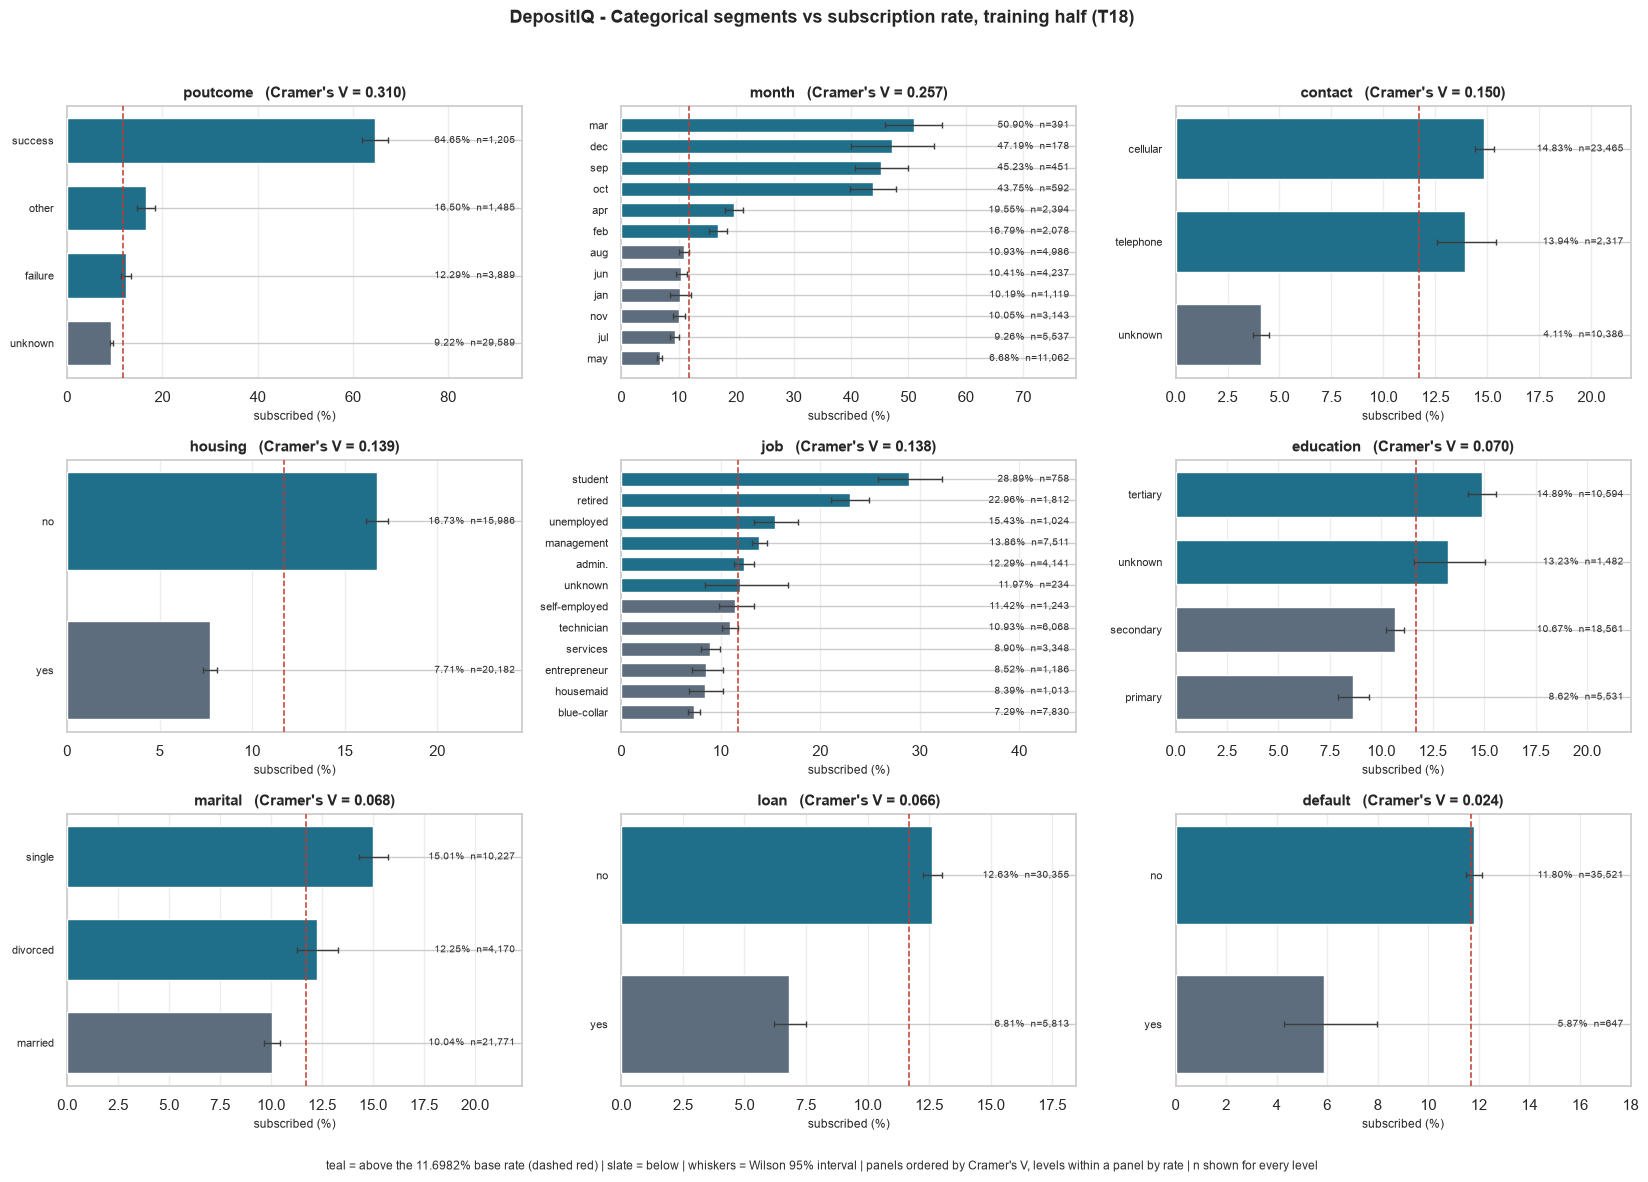

saved: reports\figures\03_categorical_vs_target.png (274 KB)


In [13]:
# One panel per categorical column, ordered by Cramer's V so the strongest association is read first.
# Bars are each level's subscription rate, sorted within the panel, with a Wilson 95% interval whisker:
# a rate standing on 178 rows and a rate standing on 29,589 must not be read with equal confidence.
# The dashed line is the base rate, so "above" and "below" are visible without reading the axis.
ABOVE, BELOW, INK = "#1f6f8b", "#5d6d7e", "#2f2f2f"

fig, axes = plt.subplots(3, 3, figsize=(16.6, 11.8))
for ax, col in zip(axes.ravel(), category_rank.index):
    block = segment_profile[segment_profile["column"] == col].sort_values("rate")
    positions = np.arange(len(block))
    ax.barh(positions, block["rate"] * 100, height=0.66, zorder=3,
            color=[ABOVE if value > rate else BELOW for value in block["rate"]])
    ax.errorbar(block["rate"] * 100, positions,
                xerr=[(block["rate"] - block["ci_low"]) * 100,
                      (block["ci_high"] - block["rate"]) * 100],
                fmt="none", ecolor="#3c3c3c", elinewidth=1.0, capsize=2.4, zorder=4)
    ax.axvline(rate * 100, color="#c0392b", linestyle="--", linewidth=1.1, zorder=5)

    ax.set_yticks(positions)
    ax.set_yticklabels(block["level"], fontsize=8)
    # The axis is per panel, scaled to that column's own range, because `poutcome` reaches 64.65% and
    # `default` 11.80% - a shared axis would flatten eight of nine panels into invisible slivers. The
    # base-rate line and the V in each title are what keep the panels comparable.
    ax.set_xlim(0, max(block["ci_high"].max() * 100 * 1.42, 18))
    for position, (_, row) in zip(positions, block.iterrows()):
        ax.text(ax.get_xlim()[1] * 0.985, position,
                # `rate` is a fraction, so the label multiplies by 100 exactly as the bar length
                # does; formatting the fraction directly printed 0.65% beside a 64.65% bar.
                f"{row['rate'] * 100:.2f}%  n={int(row['n']):,}",
                ha="right", va="center", fontsize=7.2, color=INK, zorder=6)
    ax.set_title(f"{col}   (Cramer's V = {block['cramer_v'].iloc[0]:.3f})",
                 fontsize=11, weight="bold")
    ax.set_xlabel("subscribed (%)", fontsize=8.5)
    ax.grid(axis="x", alpha=0.35, zorder=0)
    ax.set_axisbelow(True)

fig.suptitle("DepositIQ - Categorical segments vs subscription rate, training half (T18)",
             fontsize=13, weight="bold", y=0.995)
fig.text(0.5, 0.012,
         f"teal = above the {rate:.4%} base rate (dashed red) | slate = below | whiskers = Wilson 95% "
         f"interval | panels ordered by Cramer's V, levels within a panel by rate | n shown for every level",
         ha="center", fontsize=8.5, color="#2f2f2f")
fig.tight_layout(rect=(0, 0.03, 1, 0.975))
categorical_figure_path = config.FIGURES_DIR / "03_categorical_vs_target.png"
fig.savefig(categorical_figure_path, dpi=150, bbox_inches="tight")
plt.show()
print("saved:", categorical_figure_path.relative_to(REPO_ROOT),
      f"({categorical_figure_path.stat().st_size / 1024:.0f} KB)")

> **Viva line for this figure:** *the best-performing segment — a client whose previous campaign ended
> in success — subscribes at 64.65%, against a 4.11% floor for clients who were reached without a
> contact record: a 15.7-fold gap. Yet the month that carries most of the bank's effort, `may` with
> 30.59% of all calls, converts at 6.68% — just over half the base rate.*

### 3.1 The best and the worst segment, with their rates

- **Best: `poutcome = success` — 779 of 1,205 clients subscribed, 64.65%** (Wilson 95% interval
  61.91%–67.30%), **5.53×** the base rate. It is only **3.33%** of the half, yet it supplies
  **18.41%** of all 4,231 subscribers — the highest concentration anywhere in this table.
- **Worst: `contact = unknown` — 427 of 10,386 clients, 4.11%** (3.75%–4.51%), **0.35×** the base
  rate. Unlike most extremes this one is *not* a small-sample artefact: it is **28.72%** of the half,
  so its interval is under one point wide, and it still supplies **10.09%** of all subscribers.
- **The gap is 15.7×** (64.65% against 4.11%), and it sits on the two segments whose intervals barely
  overlap — the rare case in this table where both the effect size and the uncertainty agree.

Two runner-ups matter because they describe the *client* rather than the campaign: `job = student`
converts at **28.89%** (219/758) against `job = blue-collar` at **7.29%** (571/7,830), a 3.96× spread
on occupation alone, and `housing = no` at **16.73%** (2,675/15,986) against `housing = yes` at
**7.71%** (1,556/20,182).

The largest level in the table is barely a segment at all: `default = no` holds 35,521 rows —
**98.21% of the half** — so its 11.80% rate is the base rate wearing a label. The largest level that
still carries information is **`poutcome = unknown`, 29,589 rows (81.81% of the half), converting at
9.22%** — 0.79× the base rate. The strongest column in the ranking therefore still leaves five clients
in six inside one bucket it cannot split, and that bucket sits below average. Within `month`, the
largest level is **`may`, 11,062 rows (30.59%) at 6.68%**, 0.57× the base rate — nearly a third of the
campaign's effort in its worst-performing month. Whether that is timing or simply the volume the bank
was willing to spend in May is T19's question, not this section's.

### 3.2 What holds up, and what only looks like it does

**The ranking has a clear top two and a tied middle.** In Cramér's V — which for a binary outcome
reduces to `sqrt(chi2 / n)` and is therefore comparable across 2- to 12-level columns — `poutcome`
leads at **0.3102** and `month` follows at **0.2573**. After that come `contact` 0.1500, `housing`
0.1393 and `job` 0.1378, which should be read as **tied**: V rewards degrees of freedom, and `job`
spends 11 of them to land where `housing` lands with 1. `default` is last at **0.0241**.

Three cautions the measurements force on the rest of this section:

- **The highest rates sit on the smallest segments.** The four best months — `mar` 50.90%, `dec`
  47.19%, `sep` 45.23%, `oct` 43.75% — are also the four smallest, at 391, 178, 451 and 592 rows,
  **4.46% of the half between them**. `dec`'s interval runs from **39.99% to 54.51%**, wide enough to
  cover any of the others, and the ordering *inside* the group even flips once never-contacted clients
  are separated (`sep` falls below `oct`). The group is convincingly above the base rate; its internal
  ranking is noise, and no business action should be built on "October beats September".
- **A real effect can still be a small one.** `default = yes` converts at **5.87%** against 11.80%
  for `default = no`, and that difference is not chance (χ² = 21.1, p = 4.4e-06): its interval
  4.31%–7.96% excludes the base rate. Yet it covers 647 rows, **1.79%** of the half, so it has the
  smallest V in the table. Significance answers "is this distinguishable from chance"; it does not
  answer "does this matter".
- **`month` is not a stand-in for prior success.** The obvious confound is that the small high-rate
  months are enriched in `poutcome = success` clients (`dec` 23.60% and `sep` 21.73%, against 3.33%
  of the half). Restricting to the **29,589 never-contacted clients**, whose own base rate is 9.22%,
  leaves the pattern standing: `mar` 50.00% (124/248), `dec` 43.02%, `sep` 38.03%, `oct` 38.41%, and
  `may` last at 5.51%. The timing effect is its own signal, not composition.

In [14]:
# Evidence: every number §3.1-§3.3 and the figure annotations state must come from the training half.
assert len(TRAIN) == 36168
assert len(CATEGORICAL) == 9 and sorted(CATEGORICAL) == sorted(EXPECTED_CATEGORICAL)
assert len(segment_profile) == 44                                    # the 9 columns' levels
assert (segment_profile.groupby("column")["n"].sum() == n_total).all()   # each column covers every row
assert (segment_profile.groupby("column")["yes"].sum() == n_yes).all()    # and every positive

# association strength: the leading pair, the tied middle, and the weakest
assert category_rank.index[0] == "poutcome" and abs(category_rank["cramer_v"].iloc[0] - 0.3102) < 5e-4
assert category_rank.index[1] == "month" and abs(category_rank["cramer_v"].iloc[1] - 0.2573) < 5e-4
assert set(category_rank.index[2:5]) == {"contact", "housing", "job"}
assert category_rank.loc[["contact", "housing", "job"], "cramer_v"].between(0.13, 0.16).all()
assert category_rank.index[-1] == "default" and abs(category_rank["cramer_v"].iloc[-1] - 0.0241) < 5e-4
assert int(category_rank.loc["job", "dof"]) == 11 and int(category_rank.loc["housing", "dof"]) == 1

# the best and the worst, with their rates
assert best_segment["column"] == "poutcome" and best_segment["level"] == "success"
assert int(best_segment["n"]) == 1205 and int(best_segment["yes"]) == 779
assert abs(best_segment["rate"] - 0.646473) < 5e-6 and abs(best_segment["lift"] - 5.53) < 5e-3
assert worst_segment["column"] == "contact" and worst_segment["level"] == "unknown"
assert int(worst_segment["n"]) == 10386 and int(worst_segment["yes"]) == 427
assert abs(worst_segment["rate"] - 0.041113) < 5e-6 and abs(worst_segment["lift"] - 0.35) < 5e-3
assert abs(best_segment["rate"] / worst_segment["rate"] - 15.72) < 5e-3
assert worst_segment["ci_width_pp"] < 1.0                            # not a small-sample artefact
assert abs(best_segment["yes"] / n_yes - 0.184117) < 5e-6            # 18.41% of all subscribers
assert abs(worst_segment["yes"] / n_yes - 0.100922) < 5e-6           # 10.09% of all subscribers

# the four high-rate months are the four smallest, and their intervals overlap
small_months = segment_profile[(segment_profile["column"] == "month") & (segment_profile["n"] < 600)]
assert len(small_months) == 4 and int(small_months["n"].sum()) == 1612
assert abs(small_months["n"].sum() / n_total - 0.04457) < 5e-5
dec_month = small_months[small_months["level"] == "dec"].iloc[0]
assert int(dec_month["n"]) == 178 and int(dec_month["yes"]) == 84
assert abs(dec_month["ci_low"] - 0.399943) < 5e-5 and abs(dec_month["ci_high"] - 0.545064) < 5e-5


def segment(col: str, level: str) -> pd.Series:
    """The one row of `segment_profile` for a named segment, so the claims below name their evidence."""
    return segment_profile[(segment_profile["column"] == col)
                           & (segment_profile["level"] == level)].iloc[0]


# the runner-ups and the largest segment
assert int(segment("job", "student")["n"]) == 758 and int(segment("job", "student")["yes"]) == 219
assert abs(segment("job", "student")["rate"] - 0.288918) < 5e-6
assert abs(segment("job", "blue-collar")["rate"] - 0.072925) < 5e-6
assert abs(segment("job", "student")["rate"] / segment("job", "blue-collar")["rate"] - 3.96) < 5e-3
assert int(segment("housing", "no")["yes"]) == 2675 and int(segment("housing", "no")["n"]) == 15986
assert abs(segment("housing", "no")["rate"] - 0.167334) < 5e-6
assert int(segment("housing", "yes")["n"]) == 20182
assert abs(segment("housing", "yes")["rate"] - 0.077099) < 5e-6
assert int(biggest_segment["n"]) == 35521 and biggest_segment["level"] == "no"
assert abs(biggest_segment["share"] - 0.982109) < 5e-6                  # 98.21%: barely a segment
assert int(biggest_month["n"]) == 11062 and biggest_month["level"] == "may"
assert abs(segment("month", "may")["rate"] - 0.066805) < 5e-6
assert abs(segment("month", "may")["share"] - 0.30585) < 5e-5
assert abs(segment("month", "may")["rate"] / rate - 0.57) < 5e-3
assert abs(segment("month", "mar")["rate"] - 0.508951) < 5e-6
assert int(segment("default", "yes")["n"]) == 647 and abs(segment("default", "yes")["rate"] - 0.058733) < 5e-6
assert segment("default", "yes")["ci_low"] > 0 and segment("default", "yes")["ci_high"] < rate

# the never-contacted control: month survives, so it is not prior-success composition
assert len(never_contacted) == 29589 and int(y.loc[never_contacted.index].sum()) == 2729
assert abs(y.loc[never_contacted.index].mean() - 0.0922302) < 5e-7
assert abs(month_within_never["mar"] - 0.50) < 1e-9                  # exactly 124 of 248
assert abs(month_within_never["dec"] - 0.430233) < 5e-6
assert abs(month_within_never["sep"] - 0.380282) < 5e-6
assert abs(month_within_never["oct"] - 0.384127) < 5e-6
assert abs(month_within_never["may"] - 0.055125) < 5e-6
assert month_within_never["sep"] < month_within_never["oct"]        # the order flips in the control
assert (TRAIN.loc[TRAIN["month"] == "dec", "poutcome"] == "success").mean() > 0.23
assert (TRAIN.loc[TRAIN["month"] == "sep", "poutcome"] == "success").mean() > 0.21

# poutcome's unknown level is not D21's flag: the two differ on exactly five rows
assert len(orphan_rows) == 5 and int(y.loc[orphan_rows.index].sum()) == 2
assert int(TRAIN["previously_contacted"].sum()) == 6584
assert int((TRAIN["poutcome"] != "unknown").sum()) == 6579
assert not ((TRAIN["poutcome"] != "unknown") & (TRAIN["previous"] == 0)).any()
assert (orphan_rows["pdays"] != -1).all() and (orphan_rows["previous"] > 0).all()

# the figure itself
assert categorical_figure_path.exists() and categorical_figure_path.stat().st_size > 30_000
assert categorical_figure_path.name == "03_categorical_vs_target.png"
print("evidence: 59 assertion lines pass")

evidence: 59 assertion lines pass


### 3.3 What this hands to the next tasks

- **T19 (campaign and history)** owns `contact` and `month`, which describe the call rather than the
  client — and owns the awkward part of both: `contact = unknown` is simultaneously the worst segment
  in this table (4.11%) and 28.72% of the rows, so "we have no contact record" is itself a targeting
  signal, not a gap to fill in.
- **T20 (correlation heatmap)** will show none of this, because Pearson and Cramér's V measure
  different column types. §3 is the evidence for the categorical half of the feature ranking, and the
  heatmap covers only the numeric half.
- **T23/T24 (features and the `ColumnTransformer`)** should keep `poutcome`'s four levels apart
  rather than collapsing it to a contacted/not flag: `success` converts at 64.65% against 12.29% for
  `failure`, which is a large difference *inside* one column. And prior contact must be represented by
  `previously_contacted` (D21), **not** by `poutcome != unknown` — those differ on exactly **5 rows**
  (6,584 flagged by D21 against 6,579 with a known outcome), all of which have `previous > 0` and a
  valid `pdays` but no recorded outcome, and 2 of which subscribed. The implication runs one way only: every client with a known outcome was contacted
  before (0 exceptions), but not every client contacted before has a known outcome.
- **T25 (feature selection)** starts with a testable prior: `poutcome` and `month` should survive
  selection, `default` should not, and the `contact`/`housing`/`job` tie means mutual information and
  a tree's importances may order those three differently without either being wrong.
- **Nothing here is a model result.** All 44 rates are properties of the training half; the test half
  has not been read.

## 4. Campaign, history and timing vs subscription rate (T19)

§3 measured what the **client** looks like. This section measures what the **campaign did to them**, which
is the part a campaign planner can actually change:

| | column | the question |
|---|---|---|
| **Intensity** | `campaign` | do extra calls on the same client still convert? |
| **History** | `previous`, `pdays` | does having been contacted before help? how recently? |
| **Timing** | `month`, `day`, `contact` | when the call happens, and how it is placed |

§3 already reported the marginal rates for `month` and `contact`, so §4 asks a stricter question about
them: **does the effect survive when the other columns are held fixed?** Two of §3's neighbours are
deliberately re-examined here, and neither survives — see §4.3.

The section ends in money rather than percentages, because that is what a call list is spent in:
[src/cost.py](../src/cost.py) prices a call at **€1.50** and a subscription at **€20.00**, so any call
converting below **7.50%** (D17's break-even) destroys value. That single number is the test applied to
every rate below.


In [15]:
from src import cost                    # T09's cost model - the benchmark every rate below is read against

# The campaign/history set is read from the data and then checked against the list T19 names, so a
# changed dataset cannot silently remove a column this section's prose is written about.
EXPECTED_CAMPAIGN_SET = ["campaign", "previous", "pdays", "poutcome", "month", "day", "contact"]
CAMPAIGN_SET = [col for col in EXPECTED_CAMPAIGN_SET if col in TRAIN.columns]
assert CAMPAIGN_SET == EXPECTED_CAMPAIGN_SET, CAMPAIGN_SET

YES = TRAIN[config.TARGET] == config.POSITIVE_LABEL
N_TRAIN, K_TRAIN = len(TRAIN), int(YES.sum())
CALL_COST, DEPOSIT_VALUE = cost.CALL_COST_EUR, cost.VALUE_PER_SUBSCRIPTION_EUR
BREAK_EVEN = CALL_COST / DEPOSIT_VALUE                       # D17: the rate a call must beat
CAMP = TRAIN["campaign"]

# --- intensity ------------------------------------------------------------
# Six buckets for resolution, and a 4+ aggregate for the controls: `poutcome = success` at 10 or more
# calls holds a single row, so any claim tested on that cell would be a claim about one client.
CALL_BANDS = pd.cut(CAMP, bins=[0, 1, 2, 3, 5, 9, np.inf],
                    labels=["1", "2", "3", "4-5", "6-9", "10+"])
CALL_QUAD = pd.cut(CAMP, bins=[0, 1, 2, 3, np.inf], labels=["1", "2", "3", "4+"])
calls_band = pd.DataFrame({
    "n": CALL_BANDS.value_counts(),
    "subscribed": YES.groupby(CALL_BANDS, observed=True).sum(),
})
calls_band["rate"] = calls_band["subscribed"] / calls_band["n"]
calls_band["lift"] = calls_band["rate"] / rate
calls_band["share_of_rows"] = calls_band["n"] / N_TRAIN
calls_band["share_of_positives"] = calls_band["subscribed"] / K_TRAIN
calls_band[["ci_low", "ci_high"]] = [wilson_interval(int(k), int(n))
                                     for k, n in zip(calls_band["subscribed"], calls_band["n"])]
calls_band = calls_band.reindex(["1", "2", "3", "4-5", "6-9", "10+"])
# The six buckets partition the rows exactly - a stronger check than summing all 44 segments of §3.
assert calls_band["n"].sum() == N_TRAIN and calls_band["subscribed"].sum() == K_TRAIN

# --- the call budget, split at the third call ------------------------------
CAP = 3
within_cap, beyond_cap = CAMP <= CAP, CAMP > CAP
calls_within = int(CAMP[within_cap].sum())                  # every call the light clients received
calls_beyond = int((CAMP[beyond_cap] - CAP).sum())          # only the calls past their third
calls_total = int(CAMP.sum())
successes_within = int(YES[within_cap].sum())
successes_beyond = int(YES[beyond_cap].sum())
# The identity that makes `calls_beyond` the right figure for "calls a cap of three would remove": the
# heavy clients' first three calls are spent either way and are not part of the saving.
assert calls_within + int(CAMP[beyond_cap].sum()) == calls_total
assert calls_beyond == int(CAMP[beyond_cap].sum()) - CAP * int(beyond_cap.sum())

budget = pd.DataFrame([
    {"region": f"calls 1-{CAP} (all clients)", "calls": calls_within,
     "subscribed": successes_within, "rate": successes_within / calls_within,
     "clients": int(within_cap.sum())},
    {"region": f"calls {CAP + 1}+ (extra only)", "calls": calls_beyond,
     "subscribed": successes_beyond, "rate": successes_beyond / calls_beyond,
     "clients": int(beyond_cap.sum())},
])
budget["cost_eur"] = budget["calls"] * CALL_COST
budget["value_eur"] = budget["subscribed"] * DEPOSIT_VALUE
budget["net_eur"] = budget["value_eur"] - budget["cost_eur"]
budget["calls_per_success"] = budget["calls"] / budget["subscribed"]
# The claim the section rests on: the first three calls clear break-even, the extras do not.
assert budget.loc[0, "rate"] > BREAK_EVEN > budget.loc[1, "rate"]
assert budget.loc[0, "net_eur"] > 0 > budget.loc[1, "net_eur"]

# --- where the extra calls go, and what they are worth inside each group ---
tail = pd.DataFrame([
    {"group": "all clients", "clients": N_TRAIN, "extra_calls": calls_beyond,
     "extra_successes": successes_beyond},
] + [
    {"group": label, "clients": int(mask.sum()),
     "extra_calls": int((CAMP[mask & beyond_cap] - CAP).sum()),
     "extra_successes": int(YES[mask & beyond_cap].sum())}
    for label, mask in (
        ("poutcome = success", TRAIN["poutcome"].eq("success")),
        ("poutcome = unknown", TRAIN["poutcome"].eq("unknown")),
        ("never contacted", TRAIN["days_since_contact"].isna()),
    )
])
tail["rate"] = tail["extra_successes"] / tail["extra_calls"]
tail["cost_per_extra_success"] = tail["extra_calls"] / tail["extra_successes"] * CALL_COST
tail["beats_break_even"] = tail["rate"] > BREAK_EVEN

# --- history --------------------------------------------------------------
PREV_BANDS = pd.cut(TRAIN["previous"], bins=[-1, 0, 1, 2, np.inf], labels=["0", "1", "2", "3+"])
prev_band = pd.DataFrame({
    "n": PREV_BANDS.value_counts(),
    "subscribed": YES.groupby(PREV_BANDS, observed=True).sum(),
})
prev_band["rate"] = prev_band["subscribed"] / prev_band["n"]
prev_band[["ci_low", "ci_high"]] = [wilson_interval(int(k), int(n))
                                    for k, n in zip(prev_band["subscribed"], prev_band["n"])]
prev_band = prev_band.reindex(["0", "1", "2", "3+"])
assert prev_band["n"].sum() == N_TRAIN
# `previous > 0` and "has a days_since_contact" are the same 6,584 clients, so `previous = 0` is exactly
# the never-contacted group and the two tables below must agree on its size and its rate.
never = TRAIN["days_since_contact"].isna()
assert int(prev_band.loc["0", "n"]) == int(never.sum()) == int((TRAIN["previous"] == 0).sum())
assert abs(prev_band.loc["0", "rate"] - YES[never].mean()) < 1e-12

# --- recency --------------------------------------------------------------
RECENCY_BANDS = pd.cut(TRAIN["days_since_contact"], bins=[-np.inf, 30, 90, 180, np.inf],
                       labels=["<=30", "31-90", "91-180", ">180"])
recent = pd.DataFrame({
    "n": RECENCY_BANDS.value_counts(),
    "subscribed": YES.groupby(RECENCY_BANDS, observed=True).sum(),
})
recent["rate"] = recent["subscribed"] / recent["n"]
recent[["ci_low", "ci_high"]] = [wilson_interval(int(k), int(n))
                                 for k, n in zip(recent["subscribed"], recent["n"])]
recent = recent.reindex(["<=30", "31-90", "91-180", ">180"])
# `days_since_contact` is missing exactly where the client was never contacted (D23), and is present for
# all 6,584 previously-contacted clients, so no bucket is silently empty.
assert int(recent["n"].sum()) == int((~never).sum()) == 6584

# --- timing ---------------------------------------------------------------
DAY_BANDS = pd.cut(TRAIN["day"], bins=[0, 10, 20, 31], labels=["1-10", "11-20", "21-31"])
day_band = pd.DataFrame({
    "n": DAY_BANDS.value_counts(),
    "subscribed": YES.groupby(DAY_BANDS, observed=True).sum(),
})
day_band["rate"] = day_band["subscribed"] / day_band["n"]
day_band[["ci_low", "ci_high"]] = [wilson_interval(int(k), int(n))
                                   for k, n in zip(day_band["subscribed"], day_band["n"])]
day_band = day_band.reindex(["1-10", "11-20", "21-31"])
assert day_band["n"].sum() == N_TRAIN

# `day` cannot be read as a free-standing scale: the file's months do not each span the whole month.
day_coverage = TRAIN.groupby("month", observed=True)["day"].agg(["min", "max", "nunique", "count"])
assert day_coverage["nunique"].min() < 31, "if every month spanned 31 days, `day` could stand alone"

print(f"calls placed across the half : {calls_total:,} over {N_TRAIN:,} clients "
      f"(mean {CAMP.mean():.2f} each, median {int(CAMP.median())}, max {int(CAMP.max())})")
print(f"break-even rate (D17)        : {BREAK_EVEN:.4%} = EUR {CALL_COST:.2f} a call "
      f"/ EUR {DEPOSIT_VALUE:.2f} a subscription")
print()
print("INTENSITY - subscription rate by calls placed on that client")
print(calls_band.to_string(formatters={"rate": "{:.2%}".format, "lift": "{:.2f}".format,
                                       "ci_low": "{:.2%}".format, "ci_high": "{:.2%}".format,
                                       "share_of_rows": "{:.2%}".format,
                                       "share_of_positives": "{:.2%}".format}))
print()
print("CALL BUDGET - what each region of the call list is worth")
print(budget.to_string(index=False, formatters={"rate": "{:.4%}".format,
                                                "cost_eur": "{:,.0f}".format,
                                                "value_eur": "{:,.0f}".format,
                                                "net_eur": "{:,.0f}".format,
                                                "calls_per_success": "{:.1f}".format}))
print()
print("The same extra calls, inside each group")
print(tail.to_string(index=False, formatters={"rate": "{:.2%}".format,
                                              "cost_per_extra_success": "{:.2f}".format}))
print()
print("HISTORY - rate by contacts before this campaign")
print(prev_band.to_string(formatters={"rate": "{:.2%}".format, "ci_low": "{:.2%}".format,
                                      "ci_high": "{:.2%}".format}))
print()
print("RECENCY - rate by days since the previous contact (missing = never contacted, see below)")
print(recent.to_string(formatters={"rate": "{:.2%}".format, "ci_low": "{:.2%}".format,
                                   "ci_high": "{:.2%}".format}))
print(f"  never contacted: {int(never.sum()):,} clients, {YES[never].mean():.2%}")
print()
print("TIMING - rate by day of month")
print(day_band.to_string(formatters={"rate": "{:.2%}".format, "ci_low": "{:.2%}".format,
                                     "ci_high": "{:.2%}".format}))
print()
print("day coverage per month (a month that never reaches day 31 cannot carry a day effect alone):")
print(day_coverage.to_string())


calls placed across the half : 99,966 over 36,168 clients (mean 2.76 each, median 2, max 63)
break-even rate (D17)        : 7.5000% = EUR 1.50 a call / EUR 20.00 a subscription

INTENSITY - subscription rate by calls placed on that client
              n  subscribed   rate lift share_of_rows share_of_positives ci_low ci_high
campaign                                                                               
1         14026        2046 14.59% 1.25        38.78%             48.36% 14.01%  15.18%
2         10023        1118 11.15% 0.95        27.71%             26.42% 10.55%  11.79%
3          4412         497 11.26% 0.96        12.20%             11.75% 10.37%  12.23%
4-5        4224         366  8.66% 0.74        11.68%              8.65%  7.85%   9.55%
6-9        2321         154  6.64% 0.57         6.42%              3.64%  5.69%   7.72%
10+        1162          50  4.30% 0.37         3.21%              1.18%  3.28%   5.63%

CALL BUDGET - what each region of the call list is worth

In [16]:
# Four of §4's claims are tested here instead of assumed, because §3 already found one marginal pattern
# that dissolved under a control (`month`'s ordering) and the same trap is waiting in `campaign`
# (the heavy-calling months are also the low-rate months) and in `days_since_contact` (the recent buckets
# hold more prior successes). Each check holds one column fixed and re-reads the effect inside it.

# (a) `campaign` within `poutcome` - does the tail stay weak even where the base rate is high?
campaign_by_outcome = pd.crosstab(TRAIN["poutcome"], CALL_QUAD, values=YES, aggfunc="mean")
outcome_sizes = pd.crosstab(TRAIN["poutcome"], CALL_QUAD)
assert outcome_sizes.sum(axis=1).min() >= 1000, "a level with fewer rows cannot be read"
# The 4+ aggregate is used here precisely because `success` at 10+ calls holds one row.
assert int(pd.crosstab(TRAIN["poutcome"], CALL_BANDS).loc["success", "10+"]) == 1

# (b) `campaign` within `month` - the heavy-calling months (aug mean 3.94 calls, jul 3.48) are also the
# rate-poor ones, so the marginal gradient could be theirs. Read the busiest months only.
big_months = TRAIN["month"].value_counts().head(6).index.tolist()
campaign_by_month = pd.crosstab(TRAIN["month"], CALL_QUAD, values=YES, aggfunc="mean").loc[big_months]
month_cell_sizes = pd.crosstab(TRAIN["month"], CALL_QUAD).loc[big_months]
# The strong form of the claim: in every one of them the 4+ bucket converts below the one-call bucket,
# and in five of the six it is the lowest of the four buckets. `apr` is the exception, and is stated as
# one rather than rounded away: 17.72% at 4+ against 16.18% at two calls.
assert (campaign_by_month["4+"] < campaign_by_month["1"]).all()
assert (campaign_by_month["4+"] == campaign_by_month.min(axis=1)).sum() == 5

# (c) recency within `poutcome` - `poutcome = success` is 36.2% of the 31-90 day bucket against 13.0% of
# the >180 one, so a "sweet spot" could be nothing but prior successes sitting there.
recency_by_outcome = pd.crosstab(TRAIN["poutcome"], RECENCY_BANDS, values=YES, aggfunc="mean")
recency_sizes = pd.crosstab(TRAIN["poutcome"], RECENCY_BANDS)
outcome_mix_by_recency = pd.crosstab(RECENCY_BANDS, TRAIN["poutcome"], normalize="index")
# The marginal peak is at 31-90 days; inside prior successes the rate must NOT peak there.
assert recent.loc["31-90", "rate"] == recent["rate"].max()
assert recency_by_outcome.loc["success", "31-90"] < recency_by_outcome.loc["success", ">180"]

# (d) `day` within `month` - the marginal 1-10 band leads, but day ranges differ by month, so the
# difference has to be re-read inside a single month before it means anything.
day_by_month = pd.crosstab(TRAIN["month"], DAY_BANDS, values=YES, aggfunc="mean").loc[big_months]
day_cell_sizes = pd.crosstab(TRAIN["month"], DAY_BANDS).loc[big_months]
day_leads_marginally = day_band.loc["1-10", "rate"] > day_band.loc["11-20", "rate"]
day_leads_in_may = day_by_month.loc["may", "1-10"] > day_by_month.loc["may", "21-31"]
assert day_leads_marginally and not day_leads_in_may, "the day finding changed shape; re-read §4.3"

# (e) channel - does heavy calling concentrate on one channel?
channel_mix_by_band = pd.crosstab(CALL_BANDS, TRAIN["contact"], normalize="index")

print("(a) rate by calls placed, inside each prior outcome - rows = poutcome")
print(campaign_by_outcome.round(4).to_string())
print("cell sizes:")
print(outcome_sizes.to_string())
print()
print("(b) rate by calls placed inside the six busiest months")
print(campaign_by_month.round(4).to_string())
print("cell sizes:")
print(month_cell_sizes.to_string())
print()
print("(c) rate by days since contact, inside each prior outcome - rows = poutcome")
print(recency_by_outcome.round(4).to_string())
print("cell sizes:")
print(recency_sizes.to_string())
print("prior-outcome mix inside each recency bucket (the confound this check exists for):")
print(outcome_mix_by_recency.round(3).to_string())
print()
print("(d) rate by day band inside the busiest months - the marginal leader does not stay the leader")
print(day_by_month.round(4).to_string())
print("cell sizes:")
print(day_cell_sizes.to_string())
print()
print("(e) channel mix inside each call band")
print(channel_mix_by_band.round(3).to_string())


(a) rate by calls placed, inside each prior outcome - rows = poutcome
campaign       1       2       3      4+
poutcome                                
failure   0.1341  0.1118  0.1439  0.0828
other     0.1900  0.1805  0.1557  0.1017
success   0.6755  0.6127  0.6949  0.4894
unknown   0.1125  0.0889  0.0881  0.0665
cell sizes:
campaign      1     2     3    4+
poutcome                         
failure    1939  1100   403   447
other       579   399   212   295
success     678   315   118    94
unknown   10830  8209  3679  6871

(b) rate by calls placed inside the six busiest months
campaign       1       2       3      4+
month                                   
may       0.0759  0.0616  0.0783  0.0455
jul       0.0988  0.1021  0.0840  0.0820
aug       0.2442  0.0912  0.1328  0.0629
jun       0.1196  0.1246  0.0887  0.0659
nov       0.1167  0.0932  0.0784  0.0617
apr       0.2259  0.1618  0.1622  0.1772
cell sizes:
campaign     1     2     3    4+
month                           
may   

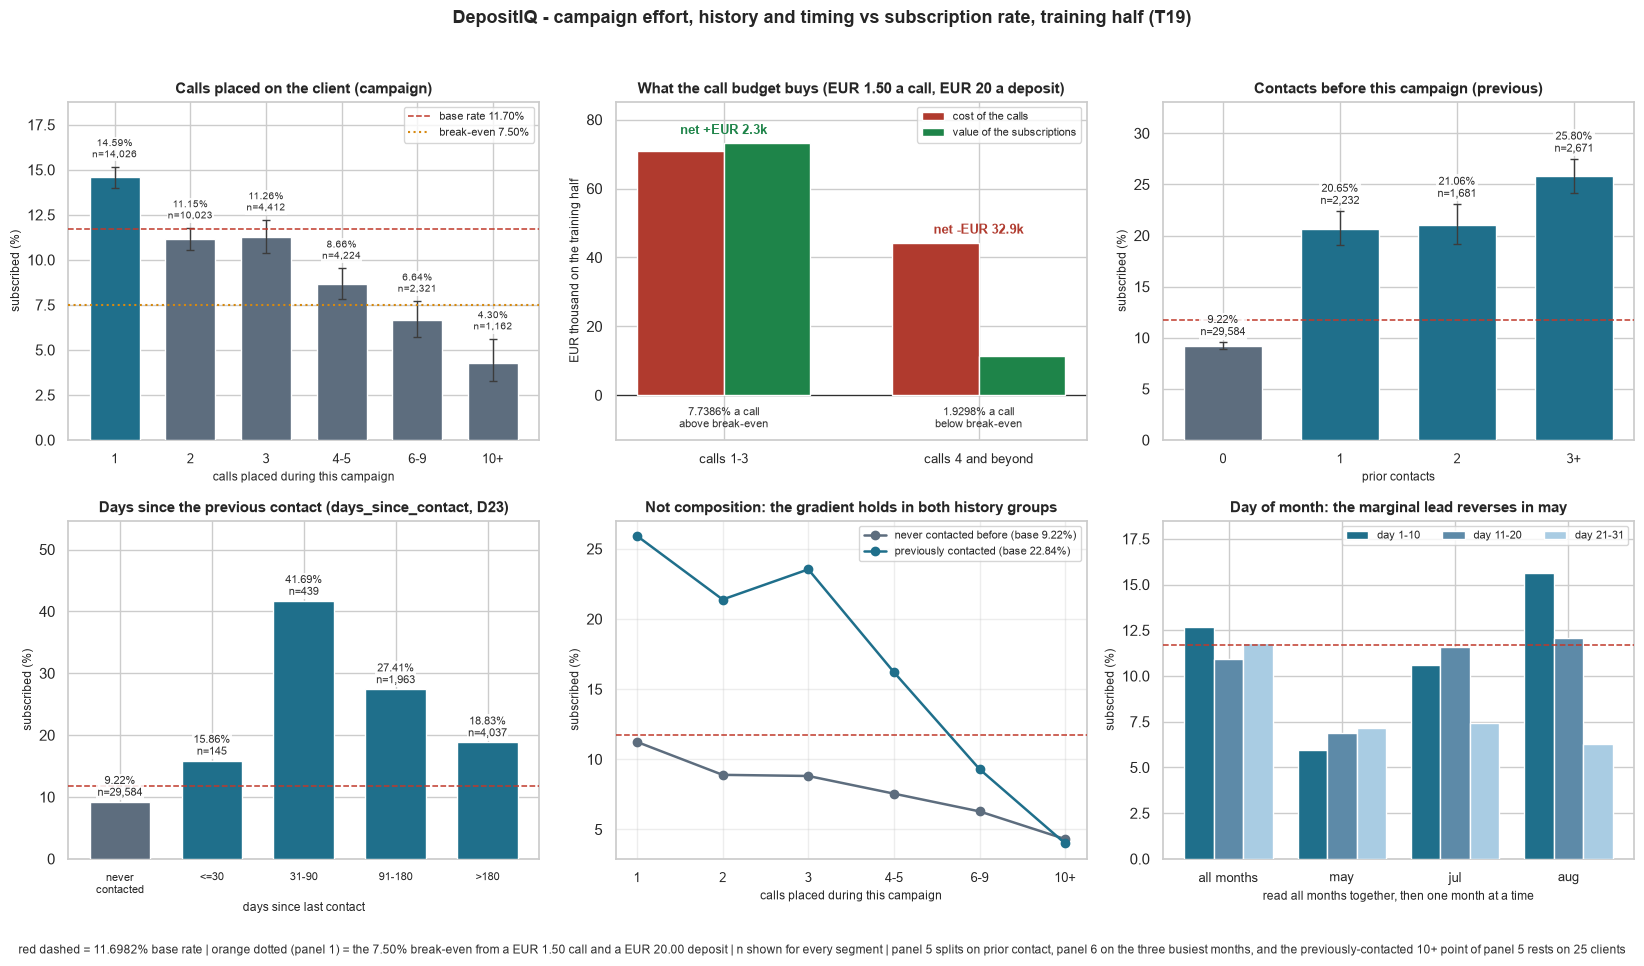

saved: reports\figures\04_campaign_vs_target.png (252 KB)


In [17]:
# Six panels: three that show an effect, one that shows where it stops paying, one robustness check and
# one negative result. The calibration is the important part - the orange dotted line in panel 1 is the
# 7.50% break-even, so a bar under it is a call that loses money whatever its base rate says.
from matplotlib.lines import Line2D

ABOVE, BELOW, INK = "#1f6f8b", "#5d6d7e", "#2f2f2f"
WARN, BREAK = "#c0392b", "#d68910"
# A white pad behind each annotation, because the base-rate line runs through the short bars' labels
# and a rate printed on top of a dashed rule is unreadable at print size.
LABEL_BOX = dict(facecolor="white", edgecolor="none", boxstyle="square,pad=0.12", alpha=0.85)

fig, axes = plt.subplots(2, 3, figsize=(16.6, 9.6))

# --- panel 1: rate by calls placed ---------------------------------------------------------------
ax = axes[0, 0]
positions = np.arange(len(calls_band))
ax.bar(positions, calls_band["rate"] * 100, width=0.66, zorder=3,
       color=[ABOVE if value > rate else BELOW for value in calls_band["rate"]])
ax.errorbar(positions, calls_band["rate"] * 100,
            yerr=[(calls_band["rate"] - calls_band["ci_low"]) * 100,
                  (calls_band["ci_high"] - calls_band["rate"]) * 100],
            fmt="none", ecolor="#3c3c3c", elinewidth=1.0, capsize=3, zorder=4)
ax.axhline(rate * 100, color=WARN, linestyle="--", linewidth=1.1, zorder=5)
ax.axhline(BREAK_EVEN * 100, color=BREAK, linestyle=":", linewidth=1.5, zorder=5)
for position, (_, row) in zip(positions, calls_band.iterrows()):
    ax.text(position, row["ci_high"] * 100 + 0.35,
            f"{row['rate'] * 100:.2f}%\nn={int(row['n']):,}", ha="center", va="bottom",
            fontsize=7.4, color=INK, zorder=6, bbox=LABEL_BOX)
# The two reference lines are named in a legend rather than by inline text, which collided with the
# 10+ error bar and made both unreadable.
ax.legend(handles=[Line2D([], [], color=WARN, linestyle="--", linewidth=1.1,
                          label=f"base rate {rate:.2%}"),
                   Line2D([], [], color=BREAK, linestyle=":", linewidth=1.5,
                          label=f"break-even {BREAK_EVEN:.2%}")],
          fontsize=8, loc="upper right")
ax.set_xticks(positions)
ax.set_xticklabels(calls_band.index, fontsize=9)
ax.set_title("Calls placed on the client (campaign)", fontsize=11, weight="bold")
ax.set_xlabel("calls placed during this campaign", fontsize=8.5)
ax.set_ylabel("subscribed (%)", fontsize=8.5)
ax.set_ylim(0, calls_band["ci_high"].max() * 100 + 3.6)

# --- panel 2: what each region of the call list is worth -------------------------------------------
ax = axes[0, 1]
positions = np.arange(len(budget))
width = 0.34
ax.bar(positions - width / 2, budget["cost_eur"] / 1000, width, label="cost of the calls",
       color="#b03a2e", zorder=3)
ax.bar(positions + width / 2, budget["value_eur"] / 1000, width, label="value of the subscriptions",
       color="#1e8449", zorder=3)
ax.axhline(0, color=INK, linewidth=0.9, zorder=2)
for position, (_, row) in zip(positions, budget.iterrows()):
    top = max(row["cost_eur"], row["value_eur"]) / 1000
    sign = "+" if row["net_eur"] > 0 else "-"
    ax.text(position, top + 1.8, f"net {sign}EUR {abs(row['net_eur']) / 1000:,.1f}k",
            ha="center", va="bottom", fontsize=9.5, weight="bold",
            color="#1e8449" if row["net_eur"] > 0 else "#b03a2e", zorder=6)
    verdict = "above break-even" if row["rate"] > BREAK_EVEN else "below break-even"
    ax.text(position, -3.2, f"{row['rate']:.4%} a call\n{verdict}", ha="center", va="top",
            fontsize=8, color=INK, zorder=6)
ax.set_xticks(positions)
ax.set_xticklabels(["calls 1-3", "calls 4 and beyond"], fontsize=9)
ax.set_title("What the call budget buys (EUR 1.50 a call, EUR 20 a deposit)", fontsize=11,
             weight="bold")
ax.set_ylabel("EUR thousand on the training half", fontsize=8.5)
ax.legend(fontsize=8, loc="upper right")
ax.set_ylim(-13, max(budget["cost_eur"].max(), budget["value_eur"].max()) / 1000 + 12)

# --- panel 3: rate by prior contacts --------------------------------------------------------------
ax = axes[0, 2]
positions = np.arange(len(prev_band))
ax.bar(positions, prev_band["rate"] * 100, width=0.66, zorder=3,
       color=[ABOVE if value > rate else BELOW for value in prev_band["rate"]])
ax.errorbar(positions, prev_band["rate"] * 100,
            yerr=[(prev_band["rate"] - prev_band["ci_low"]) * 100,
                  (prev_band["ci_high"] - prev_band["rate"]) * 100],
            fmt="none", ecolor="#3c3c3c", elinewidth=1.0, capsize=3, zorder=4)
ax.axhline(rate * 100, color=WARN, linestyle="--", linewidth=1.1, zorder=5)
for position, (_, row) in zip(positions, prev_band.iterrows()):
    ax.text(position, row["ci_high"] * 100 + 0.4,
            f"{row['rate'] * 100:.2f}%\nn={int(row['n']):,}", ha="center", va="bottom",
            fontsize=8, color=INK, zorder=6, bbox=LABEL_BOX)
ax.set_xticks(positions)
ax.set_xticklabels(prev_band.index, fontsize=9)
ax.set_title("Contacts before this campaign (previous)", fontsize=11, weight="bold")
ax.set_xlabel("prior contacts", fontsize=8.5)
ax.set_ylabel("subscribed (%)", fontsize=8.5)
ax.set_ylim(0, prev_band["ci_high"].max() * 100 + 5.6)

# --- panel 4: recency, with the never-contacted group shown as its own bar -------------------------
ax = axes[1, 0]
labels = ["never\ncontacted"] + list(recent.index)
values = [YES[never].mean()] + list(recent["rate"])
sizes = [int(never.sum())] + [int(v) for v in recent["n"]]
positions = np.arange(len(labels))
ax.bar(positions, [v * 100 for v in values], width=0.66, zorder=3,
       color=[BELOW] + [ABOVE if v > rate else BELOW for v in recent["rate"]])
ax.axhline(rate * 100, color=WARN, linestyle="--", linewidth=1.1, zorder=5)
for position, value, size in zip(positions, values, sizes):
    ax.text(position, value * 100 + 0.5, f"{value * 100:.2f}%\nn={size:,}", ha="center",
            va="bottom", fontsize=7.6, color=INK, zorder=6, bbox=LABEL_BOX)
ax.set_xticks(positions)
ax.set_xticklabels(labels, fontsize=8)
ax.set_title("Days since the previous contact (days_since_contact, D23)", fontsize=11,
             weight="bold")
ax.set_xlabel("days since last contact", fontsize=8.5)
ax.set_ylabel("subscribed (%)", fontsize=8.5)
ax.set_ylim(0, max(values) * 100 + 13)

# --- panel 5: the robustness check - the gradient holds inside both history groups -----------------
ax = axes[1, 1]
for label, mask, colour in (("never contacted before", never, BELOW),
                            ("previously contacted", ~never, ABOVE)):
    block = pd.DataFrame({"n": CALL_BANDS[mask].value_counts(),
                          "k": YES[mask].groupby(CALL_BANDS, observed=True).sum()})
    block = block.reindex(["1", "2", "3", "4-5", "6-9", "10+"])
    block["rate"] = block["k"] / block["n"]
    ax.plot(np.arange(len(block)), block["rate"] * 100, marker="o", linewidth=1.8,
            color=colour, label=f"{label} (base {YES[mask].mean():.2%})", zorder=4)
ax.axhline(rate * 100, color=WARN, linestyle="--", linewidth=1.1, zorder=3)
ax.set_xticks(np.arange(len(calls_band)))
ax.set_xticklabels(calls_band.index, fontsize=9)
ax.set_title("Not composition: the gradient holds in both history groups", fontsize=11,
             weight="bold")
ax.set_xlabel("calls placed during this campaign", fontsize=8.5)
ax.set_ylabel("subscribed (%)", fontsize=8.5)
ax.legend(fontsize=8)
ax.grid(alpha=0.35, zorder=0)

# --- panel 6: the negative result - `day`'s marginal lead does not survive a single month ----------
ax = axes[1, 2]
groups = ["all months", "may", "jul", "aug"]
day_colours = ["#1f6f8b", "#5d8aa8", "#a9cce3"]
width = 0.26
for offset, (band, colour) in enumerate(zip(["1-10", "11-20", "21-31"], day_colours)):
    values = [day_band.loc[band, "rate"]]
    for month in ("may", "jul", "aug"):
        values.append(day_by_month.loc[month, band])
    ax.bar(np.arange(len(groups)) + (offset - 1) * width, [v * 100 for v in values], width,
           label=f"day {band}", color=colour, zorder=3)
ax.axhline(rate * 100, color=WARN, linestyle="--", linewidth=1.1, zorder=5)
ax.set_xticks(np.arange(len(groups)))
ax.set_xticklabels(groups, fontsize=9)
ax.set_title("Day of month: the marginal lead reverses in may", fontsize=11, weight="bold")
ax.set_xlabel("read all months together, then one month at a time", fontsize=8.5)
ax.set_ylabel("subscribed (%)", fontsize=8.5)
ax.legend(fontsize=8, ncol=3)
ax.set_ylim(0, 18.5)

fig.suptitle("DepositIQ - campaign effort, history and timing vs subscription rate, training half (T19)",
             fontsize=13, weight="bold", y=0.995)
fig.text(0.5, 0.012,
         f"red dashed = {rate:.4%} base rate | orange dotted (panel 1) = the {BREAK_EVEN:.2%} break-even "
         f"from a EUR {CALL_COST:.2f} call and a EUR {DEPOSIT_VALUE:.2f} deposit | n shown for every "
         "segment | panel 5 splits on prior contact, panel 6 on the three busiest months, and the "
         "previously-contacted 10+ point of panel 5 rests on 25 clients",
         ha="center", fontsize=8.4, color=INK)
fig.tight_layout(rect=(0, 0.035, 1, 0.975))
campaign_figure_path = config.FIGURES_DIR / "04_campaign_vs_target.png"
fig.savefig(campaign_figure_path, dpi=150, bbox_inches="tight")
plt.show()
print("saved:", campaign_figure_path.relative_to(REPO_ROOT),
      f"({campaign_figure_path.stat().st_size / 1024:.0f} KB)")


> **Viva line for this figure:** *the campaign's fourth call onward is where the money stops working —
> the 29,537 calls placed after a client's third are worth €44,306 in agent time and return €11,400 in
> deposits, a net loss of €32,906 on the training half, while the first three calls sit just above the
> 7.50% break-even at 7.74%.*

### 4.1 One interpretation line per campaign and history variable

Each line is the number that makes the variable worth keeping or worth discounting, not a description of
its histogram.

- **`campaign`** — the number of calls placed *on this client during this campaign* (mean 2.76, median 2,
  max 63). Subscription rate falls from **14.59%** on one call to **4.30%** at ten or more, and the only
  step that is not a fall is 2 calls (11.15%) against 3 (11.26%) — a 0.11 pp difference with heavily
  overlapping intervals. Read the column as **progressively less productive effort**, not as a client
  attribute.
- **`previous`** — contacts before this campaign; **29,584 clients (81.80%) have none** and convert at
  **9.22%**, while any prior contact lifts the rate to **20.65%** at one, **21.06%** at two and **25.80%**
  at three or more. The step that matters is **0 → 1** (2.24×, non-overlapping intervals); **1 against 2
  is indistinguishable** (20.65% [19.03–22.38] against 21.06% [19.18–23.07]), so the column carries a
  flag and a mild dose effect rather than four separate levels.
- **`pdays`** — **not usable as a scale at all**: it holds the sentinel −1 for those same 29,584 rows
  (81.80%), so its median is a sentinel and its IQR is 0 (T17). Its real content is recovered as
  `days_since_contact` (D23), which is why this section reads that column and never `pdays` directly.
- **`poutcome`** — the prior campaign's result and, at V = 0.3102, §3's strongest categorical signal:
  **64.65%** for `success`, 16.50% `other`, 12.29% `failure`, 9.22% `unknown`. Unlike `previous`, its
  four levels must stay apart (D31) — and §4.2 shows the level that changes the *decision*, not just the
  ranking.
- **`month`** — pools every campaign in the file because the data carries **no year**, so its 12 levels
  are not comparable periods; **`may` alone holds 30.59% of the calls at 6.68%**, below break-even. §3
  already established that the ordering among the four small high-rate months is noise, and §4.3 adds
  why `month` is entangled with `campaign`: the heavy-calling months are `aug` (mean 3.94 calls) and
  `jul` (3.48), which are also rate-poor.
- **`day`** — **no transportable effect.** The marginal bands do differ (12.66% for days 1–10 against
  10.92% for 11–20, intervals not overlapping), but the lead **reverses inside `may`** (5.94% against
  7.14% for days 21–31), changes direction month to month (panel 6), and the column is entangled with
  `month` by construction: `jan` never runs below day 6, `feb` stops at 27, `may` starts at 4. Keep it as
  a raw feature; do not build a day rule on it.
- **`contact`** — the channel, whose §3 result this section does not overturn: `cellular` and `telephone`
  are statistically indistinguishable, so the split is *known channel against `unknown`*. `campaign` adds
  one thing to it — heavy calling concentrates on `telephone`, which is **5.2%** of the one-call clients
  and **9.7%** of the ten-or-more ones, while `cellular` slips from 65.4% to 56.8%.

### 4.2 The call budget: where the money stops working

The half's **99,966 calls** are not spread evenly. Splitting them at the third call — the point past
which the gradient has already collapsed — gives the section's decision:

- **Within three calls:** 47,308 calls, **3,661 subscriptions** (86.53% of all of them), **7.7386%** a
  call. Break-even is 7.50%, so this region is *just* profitable: **+€2,258** net.
- **Beyond three calls:** 29,537 marginal calls — the calls a cap of three would remove, since the heavy
  clients' first three are spent either way — **570 subscriptions** (13.47%), **1.9298%** a call. That is
  **3.9× below break-even**: €44,306 of agent time returns €11,400 of deposits, **−€32,906**.

So the fourth call costs **€77.73** for each extra subscription it wins, against a deposit worth €20.00.
Closing the tail loses 13.47% of the subscriptions and frees **29.55%** of the call list.

**The cap should not be applied blindly, and this is the part that changes a decision.** The same
arithmetic inside each group:

| group | extra calls beyond the third | extra subscriptions | per extra call | cost per extra subscription | beats break-even? |
|---|---|---|---|---|---|
| all clients | 29,537 | 570 | 1.93% | €77.73 | no |
| `poutcome = success` | 204 | 46 | **22.55%** | **€6.65** | **yes, 3× over** |
| `poutcome = unknown` | 27,551 | 457 | 1.66% | €90.43 | no |
| never contacted before | 27,550 | 456 | 1.66% | €90.62 | no |

**93.28% of the tail's calls (27,551 of 29,537) go to clients with no known prior outcome**, so almost the
whole loss sits in one group — while clients whose prior campaign succeeded still return **22.55%** a call,
three times break-even. The actionable rule is therefore *cap clients with no known prior outcome at three
calls; keep calling the ones whose last campaign converted*.

**What this section does not claim.** A client recorded at six calls is, by definition, one who declined
five times, so part of the gradient *is* the definition of the column: this is an association conditional
on reaching each call count, not a randomised experiment. The decline is not merely that artefact,
because it survives inside all four prior outcomes, inside both history groups (panel 5) and in all six
busiest months. But the decision above does not need causality — whatever the reason those calls convert
at 1.93%, spending €1.50 each on them is a loss, and that holds regardless of why.

### 4.3 What survives a control, and what does not

§3 found one marginal pattern that dissolved once a control was applied, so the same trap was re-tested
here. Three claims survive; two do not.

**Survives — the `campaign` gradient is not a composition artefact.** Inside `poutcome`, the 4+ bucket is
the worst bucket in all four levels (`success` 67.55% → **48.94%**, `other` 19.00% → 10.17%, `failure`
13.41% → 8.28%, `unknown` 11.25% → 6.65%), and read inside the six busiest months it is below the one-callbucket in **all six** — `aug` most sharply (24.42% → 6.29%). It also holds inside both history groups
(panel 5): never-contacted clients fall from **11.24%** at one call to **6.29%** at six to nine, and
previously-contacted ones from **25.92%** through **16.21%** at four to five calls down to **9.29%** at
six to nine — with the `10+` point of that second curve resting on only 25 clients, which is why it is
drawn rather than quoted. This is the check that
separates "more calls cause failure" from "failing clients get more calls"; it rules out the version of
the second story that runs through the columns we can see, and §4.2's arithmetic is written so that it
does not have to choose.

**Survives — prior contact is a step, not a ramp.** `previous` = 0 (9.22%) against any prior contact
(20.65–25.80%) is the whole effect; 1 against 2 is not distinguishable. §3's `poutcome` is the sharper
version of the same thing, because it separates a prior *success* (64.65%) from a prior *failure*
(12.29%) — which `previous` cannot see.

**Does not survive — the recency "sweet spot".** Marginally, `days_since_contact` peaks at 31–90 days
(**41.69%**) and falls away on both sides, which reads like a contact-window rule. It is not one:
`poutcome = success` clients are **36.2%** of that bucket against **13.0%** of the over-180 bucket, and
inside `poutcome = success` the rate does not peak there at all — it runs **62.89% → 64.52% → 66.48%** as
the contact gets *older*. Once the prior outcome is known, recency adds little. The shortest bucket also
cannot carry a rule on its own: ≤30 days holds only **145 clients (23 subscriptions)**, an interval of
10.81–22.68%.

**Does not survive — the day-of-month effect.** Covered in §4.1's `day` line: a real marginal difference
that reverses inside `may` and changes sign from month to month.

**A note on the one column §3 owns that `campaign` changes.** Heavy calling is not channel-neutral: the
`telephone` share of a client's calls rises from **5.2%** at one call to **9.7%** at ten or more, while
`cellular` falls from 65.4% to 56.8%, so the expensive tail is disproportionately telephone-based.

In [18]:
# Evidence: every number §4.1-§4.3 states must be the number the training half gives. This cell asserts
# rather than prints, so prose and data cannot drift apart silently.

# §4.1 - every rate in the interpretation list
assert round(calls_band.loc["1", "rate"] * 100, 2) == 14.59
assert round(calls_band.loc["2", "rate"] * 100, 2) == 11.15
assert round(calls_band.loc["3", "rate"] * 100, 2) == 11.26
assert round(calls_band.loc["10+", "rate"] * 100, 2) == 4.30
assert round(CAMP.mean(), 2) == 2.76 and int(CAMP.median()) == 2 and int(CAMP.max()) == 63
assert round(prev_band.loc["0", "rate"] * 100, 2) == 9.22
assert round(prev_band.loc["1", "rate"] * 100, 2) == 20.65
assert round(prev_band.loc["2", "rate"] * 100, 2) == 21.06
assert round(prev_band.loc["3+", "rate"] * 100, 2) == 25.80
assert int(prev_band.loc["0", "n"]) == 29_584                      # 81.80% of the half
assert round(prev_band.loc["1", "ci_low"], 4) == 0.1903
assert round(prev_band.loc["1", "ci_high"], 4) == 0.2238
assert round(prev_band.loc["2", "ci_low"], 4) == 0.1918
assert round(prev_band.loc["2", "ci_high"], 4) == 0.2307
assert round(prev_band.loc["1", "rate"] / prev_band.loc["0", "rate"], 2) == 2.24
assert round(YES[TRAIN["poutcome"].eq("success")].mean() * 100, 2) == 64.65
assert round(YES[TRAIN["poutcome"].eq("other")].mean() * 100, 2) == 16.50
assert round(YES[TRAIN["poutcome"].eq("failure")].mean() * 100, 2) == 12.29
assert round(day_band.loc["1-10", "rate"] * 100, 2) == 12.66
assert round(day_band.loc["11-20", "rate"] * 100, 2) == 10.92
assert day_band.loc["1-10", "ci_low"] > day_band.loc["11-20", "ci_high"]
assert round(day_by_month.loc["may", "1-10"] * 100, 2) == 5.94
assert round(day_by_month.loc["may", "21-31"] * 100, 2) == 7.14
assert int(day_coverage.loc["jan", "nunique"]) == 16
assert int(day_coverage.loc["feb", "max"]) == 27 and int(day_coverage.loc["may", "min"]) == 4
assert round(TRAIN["month"].eq("may").mean() * 100, 2) == 30.59
assert round(calls_band.loc["10+", "share_of_positives"] * 100, 2) == 1.18

# §4.2 - the budget arithmetic, recomputed from the frame rather than trusted from the table above
assert calls_total == 99_966
assert calls_within == 47_308 and calls_beyond == 29_537
assert successes_within == 3_661 and successes_beyond == 570
assert round(successes_within / calls_within * 100, 4) == 7.7386
assert round(successes_beyond / calls_beyond * 100, 4) == 1.9298
assert BREAK_EVEN == 0.075 and round(CALL_COST, 2) == 1.50 and round(DEPOSIT_VALUE, 2) == 20.00
assert round(calls_beyond / successes_beyond, 1) == 51.8
assert round(calls_beyond / successes_beyond * CALL_COST, 2) == 77.73
assert round(successes_beyond / K_TRAIN * 100, 2) == 13.47
assert round(successes_within / K_TRAIN * 100, 2) == 86.53
assert round(calls_beyond / calls_total * 100, 2) == 29.55
assert round(int(CAMP[beyond_cap].sum()) / calls_total * 100, 2) == 52.68
assert budget.loc[0, "net_eur"] == 2_258 and budget.loc[1, "net_eur"] == -32_905.5
assert round(budget.loc[0, "cost_eur"], 1) == 70_962.0 and round(budget.loc[1, "cost_eur"], 1) == 44_305.5
assert round(budget.loc[0, "value_eur"], 1) == 73_220.0 and round(budget.loc[1, "value_eur"], 1) == 11_400.0
assert tail.loc[1, "cost_per_extra_success"].round(2) == 6.65
assert tail.loc[2, "cost_per_extra_success"].round(2) == 90.43
assert tail.loc[3, "cost_per_extra_success"].round(2) == 90.62
assert tail.loc[0, "beats_break_even"] == False and tail.loc[1, "beats_break_even"] == True
assert round(tail.loc[2, "extra_calls"] / calls_beyond * 100, 2) == 93.28
assert round(tail.loc[1, "rate"] * 100, 2) == 22.55
assert round(tail.loc[1, "rate"] / BREAK_EVEN, 1) == 3.0

# §4.3 - the two controls that failed to rescue the claim and the two that did
assert (campaign_by_outcome["4+"] == campaign_by_outcome.min(axis=1)).all()
assert round(campaign_by_outcome.loc["success", "4+"] * 100, 2) == 48.94
assert round(campaign_by_outcome.loc["success", "1"] * 100, 2) == 67.55
assert round(campaign_by_outcome.loc["failure", "4+"] * 100, 2) == 8.28
assert round(campaign_by_outcome.loc["unknown", "4+"] * 100, 2) == 6.65
assert round(campaign_by_month.loc["aug", "1"] * 100, 2) == 24.42
assert round(campaign_by_month.loc["aug", "4+"] * 100, 2) == 6.29
assert round(recent.loc["31-90", "rate"] * 100, 2) == 41.69
assert round(recency_by_outcome.loc["success", "31-90"] * 100, 2) == 62.89
assert round(recency_by_outcome.loc["success", "91-180"] * 100, 2) == 64.52
assert round(recency_by_outcome.loc["success", ">180"] * 100, 2) == 66.48
assert round(outcome_mix_by_recency.loc["31-90", "success"] * 100, 1) == 36.2
assert round(outcome_mix_by_recency.loc[">180", "success"] * 100, 1) == 13.0
assert int(recent.loc["<=30", "n"]) == 145 and int(recent.loc["<=30", "subscribed"]) == 23
assert round(recent.loc["<=30", "ci_low"] * 100, 2) == 10.81
assert round(recent.loc["<=30", "ci_high"] * 100, 2) == 22.68
assert round(channel_mix_by_band.loc["1", "telephone"] * 100, 1) == 5.2
assert round(channel_mix_by_band.loc["10+", "telephone"] * 100, 1) == 9.7
assert round(channel_mix_by_band.loc["1", "cellular"] * 100, 1) == 65.4
assert round(channel_mix_by_band.loc["10+", "cellular"] * 100, 1) == 56.8
# The two history groups panel 5 plots, so the figure's curve endpoints are pinned as well. The last
# point of each curve is the 10+ bucket, whose previously-contacted cell holds only 25 clients.
assert round(YES[never & CALL_BANDS.eq("1")].mean() * 100, 2) == 11.24
assert round(YES[never & CALL_BANDS.eq("6-9")].mean() * 100, 2) == 6.29
assert round(YES[never & CALL_BANDS.eq("10+")].mean() * 100, 2) == 4.31
assert round(YES[(~never) & CALL_BANDS.eq("1")].mean() * 100, 2) == 25.92
assert round(YES[(~never) & CALL_BANDS.eq("6-9")].mean() * 100, 2) == 9.29
assert round(YES[(~never) & CALL_BANDS.eq("4-5")].mean() * 100, 2) == 16.21
assert round(YES[(~never) & CALL_BANDS.eq("10+")].mean() * 100, 2) == 4.00
assert int(((~never) & CALL_BANDS.eq("10+")).sum()) == 25

# Guard rails that must keep holding after §4 is inserted.
assert config.TEST_CSV.name not in TRAIN_PATH.name
assert N_TRAIN == 36_168 and K_TRAIN == 4_231

# The assertion count is read off this cell's own source (D27) rather than typed, so it cannot drift.
import json

_t19_source = "".join(
    "".join(c["source"]) for c in json.loads((REPO_ROOT / "notebooks" / "03_eda.ipynb")
                                              .read_text(encoding="utf-8"))["cells"]
    if "T19 evidence" in "".join(c["source"]))
_t19_asserts = [line for line in _t19_source.splitlines() if line.strip().startswith("assert ")]
print(f"T19 evidence: {len(_t19_asserts)} assertions in this cell, all holding - "
      f"every number in §4.1-4.3 re-derives from {TRAIN_PATH.name}")


T19 evidence: 79 assertions in this cell, all holding - every number in §4.1-4.3 re-derives from train.csv


### 4.4 What this hands to the next tasks

- **T23 (feature engineering)** — `campaign` enters as a **productivity** column, so the honest encoding
  is a capped count or a small bucket rather than the raw 1–63 scale, and `previous` enters as a **flag**
  (D21) plus a mild count. `pdays` must not enter at all; `days_since_contact` replaces it and, per §4.3,
  is worth little once `poutcome` is present — which becomes a testable prior for T25.
- **T25 (feature selection)** — the prediction to check: `previous` and `days_since_contact` should
  **drop out** if `poutcome` survives, because §4.3 shows recency adds little conditional on the prior
  outcome. Stated as a prediction, not pre-empted as a decision.
- **T34 (threshold tuning) and T39 (recommendations)** — the cap analysis is a ready-made playbook item
  with measured numbers behind it: the tail beyond the third call loses **€32,906** on the training half,
  **93.28%** of that loss sits in the no-known-prior-outcome group, and prior successes still return
  **€6.65** per extra subscription.
- **T36 (with/without `duration`)** — unchanged; §4 deliberately used neither `duration` nor any other
  post-outcome column.
- **T20 (correlation heatmap)** is next and covers the numeric half only. `campaign`'s +4.94 skew and an
  IQR of 1 (T17) will matter there for the same reason §2 flagged it.
- **Nothing here is a model result.** Every rate above is a property of the training half; no classifier
  has been fitted and the test half has not been read.

## 5. Correlation structure and multicollinearity (T20)

§2 and §4 each described one column at a time. This section reads them **against each other**, which is
what T24's `ColumnTransformer` has to survive: a pair of columns that carry the same information does not
add a feature, it adds an unstable coefficient.

Two decisions follow from what is measured here rather than from habit:

1. **Pearson and Spearman are shown side by side**, because seven of the eight numeric columns are
   skewed (T17: `previous` +45.03 down to `day` +0.09). Where the two disagree, the disagreement is the
   finding, not a detail to be averaged away.
2. **Every correlation is annotated with the number of rows it was computed on.** Pandas' `.corr` uses
   *pairwise complete* observations, so a correlation involving `days_since_contact` rests on **6,584**
   rows while the rest rest on **36,168** — mixing them in one ranking without saying so would be a
   quiet unit change.

The target enters as a 0/1 column, which makes its Pearson correlation a **point-biserial** coefficient —
algebraically the same formula, and it is read as such, not as a claim that `y` is Gaussian.


In [19]:
# The numeric set is taken from the frame, then checked against the list T20 names.
CORR_NUMERIC = TRAIN.select_dtypes(include=np.number).columns.tolist()
EXPECTED_CORR_NUMERIC = ["age", "balance", "day", "duration", "campaign", "pdays", "previous",
                         "days_since_contact"]
assert CORR_NUMERIC == EXPECTED_CORR_NUMERIC, CORR_NUMERIC

CORR_FRAME = TRAIN[CORR_NUMERIC].copy()
CORR_FRAME["y"] = YES.astype(int)          # the target as 0/1 -> Pearson becomes point-biserial
PEARSON = CORR_FRAME.corr(method="pearson")
SPEARMAN = CORR_FRAME.corr(method="spearman")
# Pairwise-complete counts: the matrix pandas actually uses, disclosed rather than assumed.
N_MATRIX = CORR_FRAME.notna().astype(int).T.dot(CORR_FRAME.notna().astype(int))

# --- the ranking against the target -------------------------------------------------
target_corr = pd.DataFrame({
    "pearson": PEARSON["y"].drop("y"),
    "spearman": SPEARMAN["y"].drop("y"),
    "n": [int(N_MATRIX.loc[col, "y"]) for col in PEARSON.columns if col != "y"],
}).sort_values("pearson", key=abs, ascending=False)
target_corr["abs_gap"] = (target_corr["spearman"] - target_corr["pearson"]).abs()
target_corr["sign_flip"] = np.sign(target_corr["pearson"]) != np.sign(target_corr["spearman"])
target_corr["r2"] = target_corr["pearson"] ** 2

# --- pairwise structure ------------------------------------------------------------
OFF_DIAG = PEARSON.drop(index="y", columns="y")
pair_rows = [(a, b, float(OFF_DIAG.loc[a, b])) for i, a in enumerate(OFF_DIAG.index)
             for b in OFF_DIAG.index[i + 1:]]
PAIRS = pd.DataFrame(pair_rows, columns=["a", "b", "pearson"])
PAIRS["abs"] = PAIRS["pearson"].abs()
PAIRS = PAIRS.sort_values("abs", ascending=False).reset_index(drop=True)
assert len(PAIRS) == 28, len(PAIRS)                      # 8 columns -> 28 pairs
FLAGGED = PAIRS[PAIRS["abs"] >= 0.20].reset_index(drop=True)

# --- the duplicate, and what it does to the matrix ---------------------------------
IDENTICAL_MASK = TRAIN["days_since_contact"].notna()
COMPLETE = TRAIN[CORR_NUMERIC].dropna()
assert len(COMPLETE) == int(IDENTICAL_MASK.sum()) == 6584
pdays_matches_dsc = bool((COMPLETE["pdays"] == COMPLETE["days_since_contact"]).all())
R_COMPLETE = np.corrcoef(COMPLETE.to_numpy(), rowvar=False)
RANK = int(np.linalg.matrix_rank(R_COMPLETE))
COND = float(np.linalg.cond(R_COMPLETE))
assert pdays_matches_dsc and RANK == 7 and COND > 1e15
# The sentinel is what hides this: on the full column the pair still correlates at exactly 1.0, but the
# *value* of `pdays` is only equal to `days_since_contact` where the client was contacted.
assert round(float(PEARSON.loc["pdays", "days_since_contact"]), 4) == 1.0

# --- VIF, once the duplicate is removed --------------------------------------------
def vif(frame: pd.DataFrame) -> pd.Series:
    z = (frame - frame.mean()) / frame.std(ddof=0)
    return pd.Series(np.diag(np.linalg.inv(np.corrcoef(z.to_numpy(), rowvar=False))), index=frame.columns)


IMPUTED = COMPLETE.copy()                       # VIF needs complete rows; stated, not hidden
VIF_WITH = vif(IMPUTED)
VIF_WITHOUT = vif(IMPUTED.drop(columns="pdays"))
# With both columns present the inverse is numerically meaningless; once `pdays` goes, every VIF is ~1.
assert VIF_WITH["pdays"] > 1e10 and float(VIF_WITHOUT.max()) < 1.10

# --- the same column read two ways gives two signs ---------------------------------
PDAYS_FULL = float(PEARSON.loc["pdays", "y"])
PDAYS_RESTRICTED = float(TRAIN.loc[IDENTICAL_MASK, "pdays"].corr(YES[IDENTICAL_MASK]))
DSC_CORR = float(PEARSON.loc["days_since_contact", "y"])
assert round(PDAYS_FULL, 4) == 0.1007 and round(PDAYS_RESTRICTED, 4) == -0.1526
assert abs(PDAYS_RESTRICTED - DSC_CORR) < 1e-12

# --- what a straight line cannot see -----------------------------------------------
CAMP_BUCKETS = [CAMP.eq(1), CAMP.eq(2), CAMP.eq(3), CAMP.between(4, 5), CAMP.between(6, 9),
                CAMP >= 10]
grand = float(YES.mean())
eta2 = sum(m.sum() * (float(YES[m].mean()) - grand) ** 2 for m in CAMP_BUCKETS) / \
       float(((YES - grand) ** 2).sum())
linear_r2 = float(PEARSON.loc["campaign", "y"]) ** 2

print("PAIRWISE-COMPLETE COUNTS (rows behind each correlation)")
print(N_MATRIX.to_string())
print()
print("CORRELATION WITH THE TARGET, sorted by |Pearson|")
print(target_corr.to_string(formatters={"pearson": "{:+.4f}".format, "spearman": "{:+.4f}".format,
                                        "abs_gap": "{:.4f}".format, "r2": "{:.4f}".format}))
print()
print(f"PAIRS WITH |Pearson| >= 0.20 (out of {len(PAIRS)} off-diagonal pairs)")
print(FLAGGED.to_string(index=False, formatters={"pearson": "{:+.4f}".format, "abs": "{:.4f}".format}))
print()
print(f"pdays == days_since_contact on all {len(COMPLETE):,} complete rows : {pdays_matches_dsc}")
print(f"complete-case correlation matrix : rank {RANK} of {len(CORR_NUMERIC)} "
      f"(condition number {COND:.3e})")
print()
print("VIF, both degenerate columns present (the inverse is numerically meaningless):")
print(VIF_WITH.to_string(float_format="{:.3e}".format))
print("VIF with `pdays` dropped:")
print(VIF_WITHOUT.to_string(float_format="{:.4f}".format))
print()
print(f"pdays against y, whole column      : {PDAYS_FULL:+.4f}")
print(f"pdays against y, contacted rows only: {PDAYS_RESTRICTED:+.4f}")
print(f"days_since_contact against y        : {DSC_CORR:+.4f}")
print()
print(f"campaign: a straight line explains r^2 = {linear_r2:.4f} of the target's variance;")
print(f"the six buckets (T19) explain eta^2 = {eta2:.4f} - the line recovers "
      f"{linear_r2 / eta2:.0%} of the bucket structure.")


PAIRWISE-COMPLETE COUNTS (rows behind each correlation)
                      age  balance    day  duration  campaign  pdays  previous  days_since_contact      y
age                 36168    36168  36168     36168     36168  36168     36168                6584  36168
balance             36168    36168  36168     36168     36168  36168     36168                6584  36168
day                 36168    36168  36168     36168     36168  36168     36168                6584  36168
duration            36168    36168  36168     36168     36168  36168     36168                6584  36168
campaign            36168    36168  36168     36168     36168  36168     36168                6584  36168
pdays               36168    36168  36168     36168     36168  36168     36168                6584  36168
previous            36168    36168  36168     36168     36168  36168     36168                6584  36168
days_since_contact   6584     6584   6584      6584      6584   6584      6584                65

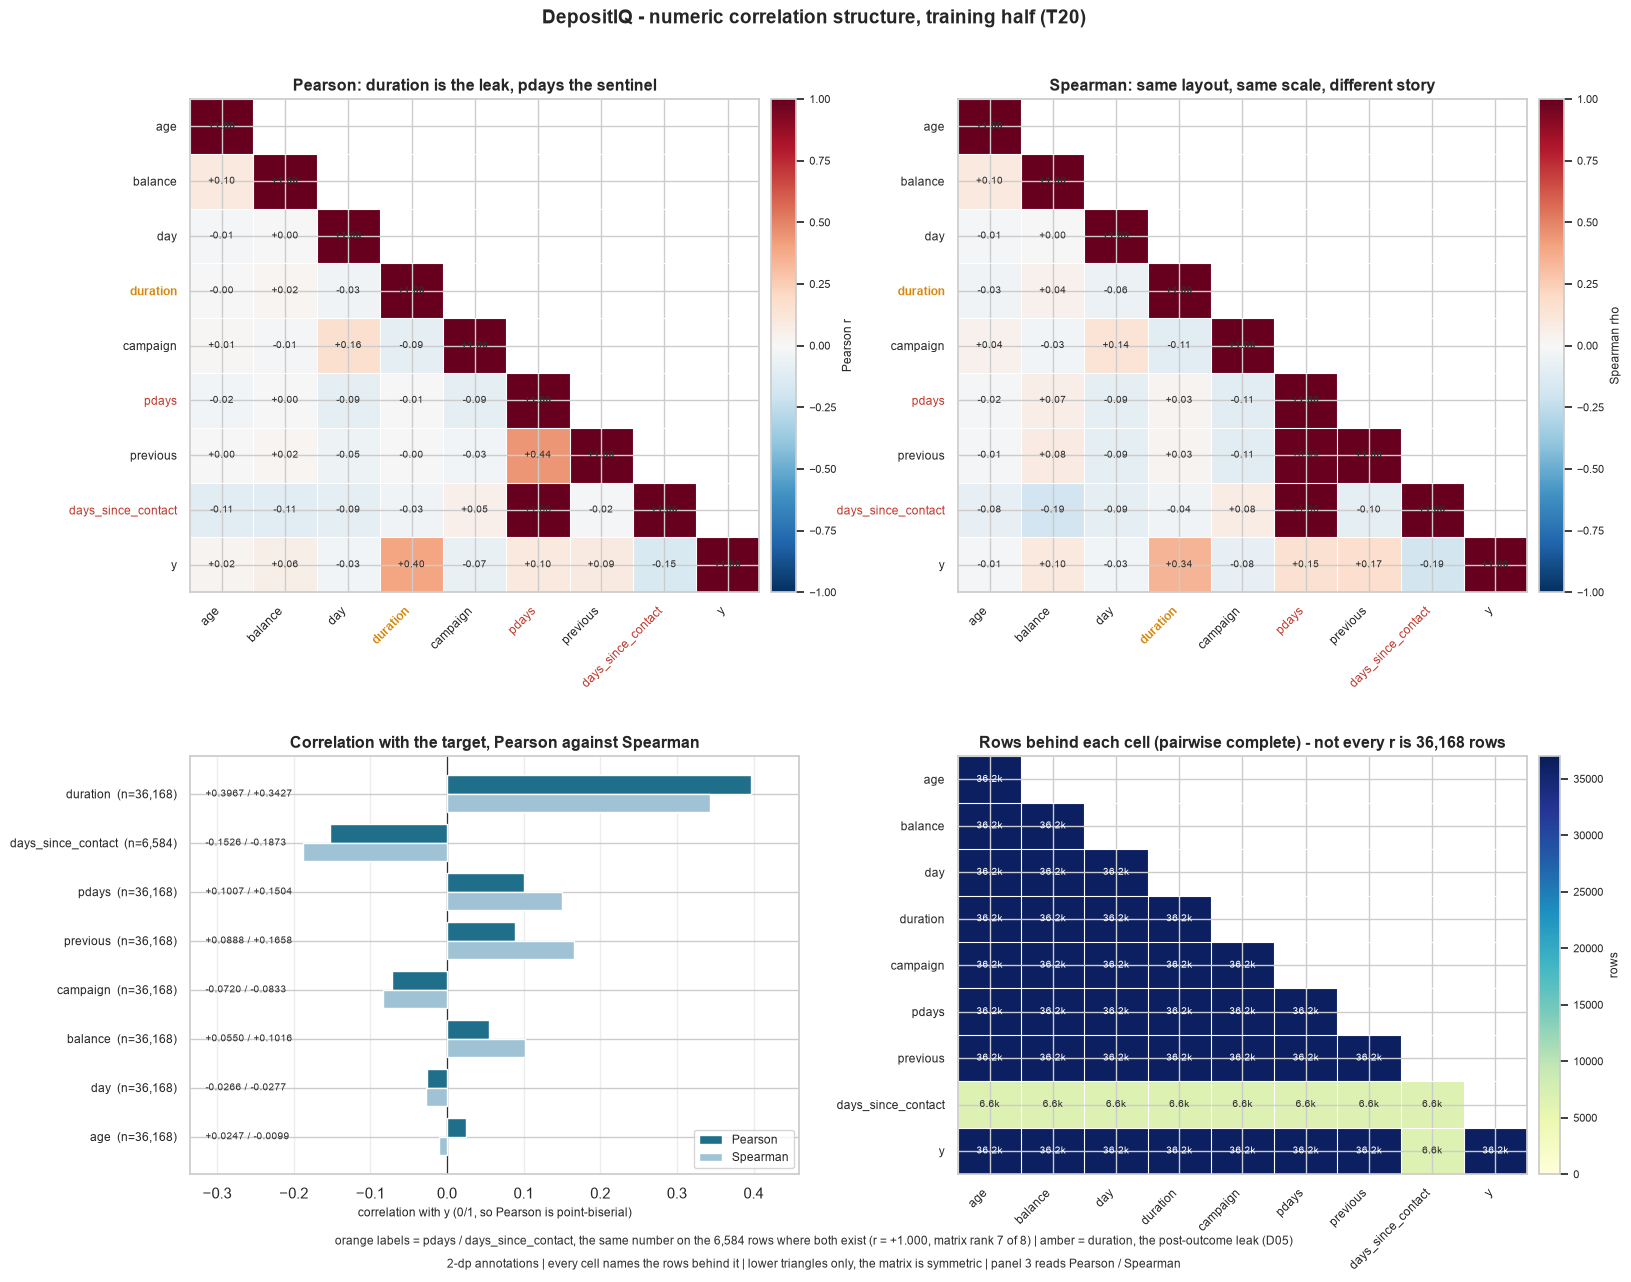

saved: reports\figures\05_correlation_heatmap.png (343 KB)


In [20]:
# Four panels: the two correlation matrices on a shared scale so their disagreement is visible, the
# target ranking with both coefficients, and the pairwise row counts that qualify everything above it.
ABOVE, BELOW, INK = "#1f6f8b", "#5d6d7e", "#2f2f2f"
WARN, BREAK = "#c0392b", "#d68910"
LABEL_BOX = dict(facecolor="white", edgecolor="none", boxstyle="square,pad=0.12", alpha=0.85)

LABELS = list(PEARSON.columns)
mask = np.triu(np.ones_like(PEARSON.to_numpy(), dtype=bool), k=1)

# The matrices are drawn with `aspect="auto"` so each one fills its cell: forcing square cells leaves
# a band of empty canvas above them and shrinks the numbers that are the point of the figure.
fig = plt.figure(figsize=(16.2, 12.8))
grid = fig.add_gridspec(2, 2, height_ratios=[1.18, 1.0], hspace=0.36, wspace=0.26)


def heat(ax, matrix, title, cmap, vmin, vmax, fmt, cbar_label):
    data = np.ma.masked_array(matrix.to_numpy(), mask=mask)
    image = ax.imshow(data, cmap=cmap, vmin=vmin, vmax=vmax, aspect="auto")
    ax.set_xticks(np.arange(len(LABELS)))
    ax.set_yticks(np.arange(len(LABELS)))
    ax.set_xticklabels(LABELS, rotation=45, ha="right", fontsize=8.6)
    ax.set_yticklabels(LABELS, fontsize=8.6)
    for tick, name in zip(ax.get_xticklabels(), LABELS):
        if name == "duration":
            tick.set_color(BREAK)
            tick.set_fontweight("bold")
        elif name in ("pdays", "days_since_contact"):
            tick.set_color(WARN)
    for tick, name in zip(ax.get_yticklabels(), LABELS):
        if name == "duration":
            tick.set_color(BREAK)
            tick.set_fontweight("bold")
        elif name in ("pdays", "days_since_contact"):
            tick.set_color(WARN)
    for i in range(len(LABELS)):
        for j in range(i + 1):
            value = matrix.iloc[i, j]
            ax.text(j, i, fmt(value), ha="center", va="center", fontsize=6.9, color=INK,
                    fontweight="bold" if i == j else "normal")
    ax.set_title(title, fontsize=11.5, weight="bold")
    ax.set_xticks(np.arange(-0.5, len(LABELS), 1), minor=True)
    ax.set_yticks(np.arange(-0.5, len(LABELS), 1), minor=True)
    ax.grid(which="minor", color="white", linewidth=0.8)
    ax.tick_params(which="minor", length=0)
    bar = fig.colorbar(image, ax=ax, fraction=0.046, pad=0.02)
    bar.set_label(cbar_label, fontsize=8.5)
    bar.ax.tick_params(labelsize=8)


heat(fig.add_subplot(grid[0, 0]), PEARSON,
     "Pearson: duration is the leak, pdays the sentinel",
     "RdBu_r", -1, 1, lambda v: f"{v:+.2f}", "Pearson r")
heat(fig.add_subplot(grid[0, 1]), SPEARMAN,
     "Spearman: same layout, same scale, different story",
     "RdBu_r", -1, 1, lambda v: f"{v:+.2f}", "Spearman rho")

# --- panel 3: the target ranking, both coefficients ---------------------------------
ax = fig.add_subplot(grid[1, 0])
order = target_corr.index.tolist()[::-1]
positions = np.arange(len(order))
height = 0.38
ax.barh(positions + height / 2, target_corr.loc[order, "pearson"], height,
        label="Pearson", color=ABOVE, zorder=3)
ax.barh(positions - height / 2, target_corr.loc[order, "spearman"], height,
        label="Spearman", color="#9fc3d4", zorder=3)
ax.axvline(0, color=INK, linewidth=0.9, zorder=2)
# Every annotation sits in one fixed left column, so a negative row cannot push its numbers into the
# tick label and the block reads as a table.
for position, name in zip(positions, order):
    row = target_corr.loc[name]
    ax.text(-0.315, position, f"{row['pearson']:+.4f} / {row['spearman']:+.4f}",
            ha="left", va="center", fontsize=7.5, color=INK, zorder=6)
ax.set_yticks(positions)
# The row count goes in the tick label, where it cannot collide with the bars.
ax.set_yticklabels([f"{name}  (n={int(target_corr.loc[name, 'n']):,})" for name in order],
                   fontsize=8.6)
ax.set_title("Correlation with the target, Pearson against Spearman", fontsize=11.5, weight="bold")
ax.set_xlabel("correlation with y (0/1, so Pearson is point-biserial)", fontsize=8.8)
ax.set_xlim(-0.335, 0.46)
ax.legend(fontsize=8.5, loc="lower right")
ax.grid(axis="x", alpha=0.35, zorder=0)
ax.set_axisbelow(True)

# --- panel 4: how many rows each correlation stands on ------------------------------
ax = fig.add_subplot(grid[1, 1])
n_data = np.ma.masked_array(N_MATRIX.to_numpy(), mask=mask)
image = ax.imshow(n_data, cmap="YlGnBu", vmin=0, vmax=37000, aspect="auto")
ax.set_xticks(np.arange(len(LABELS)))
ax.set_yticks(np.arange(len(LABELS)))
ax.set_xticklabels(LABELS, rotation=45, ha="right", fontsize=8.6)
ax.set_yticklabels(LABELS, fontsize=8.6)
for i in range(len(LABELS)):
    for j in range(i + 1):
        value = int(N_MATRIX.iloc[i, j])
        ax.text(j, i, f"{value / 1000:.1f}k", ha="center", va="center", fontsize=6.9,
                color="white" if value > 25000 else INK)
ax.set_title("Rows behind each cell (pairwise complete) - not every r is 36,168 rows",
             fontsize=11.5, weight="bold")
ax.set_xticks(np.arange(-0.5, len(LABELS), 1), minor=True)
ax.set_yticks(np.arange(-0.5, len(LABELS), 1), minor=True)
ax.grid(which="minor", color="white", linewidth=0.8)
ax.tick_params(which="minor", length=0)
bar = fig.colorbar(image, ax=ax, fraction=0.046, pad=0.02)
bar.set_label("rows", fontsize=8.5)
bar.ax.tick_params(labelsize=8)

fig.suptitle("DepositIQ - numeric correlation structure, training half (T20)", fontsize=13.5,
             weight="bold", y=0.995)
fig.text(0.5, 0.028,
         f"orange labels = pdays / days_since_contact, the same number on the {len(COMPLETE):,} rows "
         f"where both exist (r = +1.000, matrix rank {RANK} of 8) | amber = duration, the post-outcome "
         f"leak (D05)", ha="center", va="bottom", fontsize=8.6, color=INK)
fig.text(0.5, 0.010,
         "2-dp annotations | every cell names the rows behind it | lower triangles only, the matrix is "
         "symmetric | panel 3 reads Pearson / Spearman",
         ha="center", va="bottom", fontsize=8.6, color=INK)
correlation_figure_path = config.FIGURES_DIR / "05_correlation_heatmap.png"
# `tight_layout` warns that axes carrying a colorbar from an explicit gridspec are "not compatible"
# with it, and it is right to: the margins are set explicitly instead, and `bbox_inches="tight"` at
# save time does the cropping. That also keeps the inline and Agg backends rendering the same file.
fig.subplots_adjust(left=0.115, right=0.965, top=0.925, bottom=0.085)
fig.savefig(correlation_figure_path, dpi=150, bbox_inches="tight")
plt.show()
print("saved:", correlation_figure_path.relative_to(REPO_ROOT),
      f"({correlation_figure_path.stat().st_size / 1024:.0f} KB)")


> **Viva line for this figure:** *the numeric columns are nearly orthogonal — the largest off-diagonal
> correlation is +0.439 — and the one severe problem is not a correlated pair but a **duplicate column**:
> `pdays` and `days_since_contact` are the same number on all 6,584 rows where both exist, which makes the
> complete-case matrix rank 7 of 8 and hands both columns a VIF of about 9×10¹⁵.*

### 5.1 The strongest correlations with the target

Read the `n` column before the coefficient: the first row is measured on **5.5×** as many rows as the
second.

| rank | column | Pearson | Spearman | n | reading |
|---|---|---|---|---|---|
| 1 | `duration` | **+0.3967** | +0.3427 | 36,168 | **the leak (D05)** — known only after the call ends, so it measures the outcome, not a predictor |
| 2 | `days_since_contact` | **−0.1526** | −0.1873 | **6,584** | only defined for previously-contacted clients (D23); longer since last contact, lower the rate |
| 3 | `pdays` | +0.1007 | +0.1504 | 36,168 | **the same column with the sentinel in it** — see §5.3, where the sign reverses |
| 4 | `previous` | +0.0888 | +0.1658 | 36,168 | prior contacts; §4 found this is a **step** at zero, not a ramp, so a line understates it |
| 5 | `campaign` | −0.0720 | −0.0833 | 36,168 | calls placed; §4's bucket table is the honest form of this column |
| 6 | `balance` | +0.0550 | +0.1016 | 36,168 | the skew (+8.34) flattens the linear fit, which is why the rank version nearly doubles |
| 7 | `day` | −0.0266 | −0.0277 | 36,168 | both methods agree it is ~nothing — consistent with §4's finding that its marginal lead reverses |
| 8 | `age` | +0.0247 | −0.0099 | 36,168 | **the two methods disagree on the sign**, so there is no monotone relationship to report |

**Three things this table settles.** The strongest *usable* linear signal in the numeric half is
`days_since_contact` at −0.1526, and it is a third of `duration`'s — which is the quantitative reason
`duration`'s exclusion (D05) costs the project a real predictor and must be argued rather than waved
through. Second, `age` and `day` carry nothing linear, and `age` does not even carry a consistent sign,
so neither belongs in a linear model's headline. Third, `pdays` and `days_since_contact` rank 3rd and 2nd
while being **the same column** — which is possible only because one of them is measured through a
sentinel, and §5.3 quantifies the damage.

### 5.2 Multicollinearity: a duplicate column, not a correlated pair

This dataset is often described as having no multicollinearity problem, and on the usual test that is
right: of the **28** off-diagonal pairs only **two** reach |r| ≥ 0.20.

| pair | Pearson | why it exists |
|---|---|---|
| `pdays` ↔ `days_since_contact` | **+1.0000** | they are the *same number*: `days_since_contact` is `pdays` where `pdays > 0` (D23) |
| `pdays` ↔ `previous` | +0.4390 | structural: `pdays = −1` and `previous = 0` are the same 29,584 rows (identical, not merely correlated) |

The first is not a correlation to be managed, it is a **rank deficiency**. On the 6,584 complete rows the
8-column correlation matrix has **rank 7**, a condition number of **5.0×10¹⁶**, and the VIF of both
columns is **9.0×10¹⁵** — machine infinity. Drop `pdays` and every remaining VIF is between **1.01 and
1.03**: the near-orthogonality is genuine, and the duplicate was the only problem.

**Verdict for T24.** Keep **`days_since_contact`** (real scale, NaN where never contacted, so the
`ColumnTransformer` handles absence explicitly) plus **`previously_contacted`** (D21's flag), and **drop
raw `pdays`** — D36. Keeping both would let a linear model split one effect between two names, which is
exactly the instability multicollinearity is supposed to warn about, while the VIF keeps looking fine
because the duplication is masked by the sentinel.

Two further notes that matter for how the matrix is read. The `+0.4390` pair is **not** a modelling
problem but a warning about interpretation: any model containing both `pdays` and `previous` sees one
fact twice in different units. And `days_since_contact` is missing for 81.80% of rows, so its
correlation rests on 6,584 rows while everything else rests on 36,168 — which is why the fourth panel
plots the counts rather than leaving them in a docstring.

### 5.3 What a correlation matrix cannot see

Three findings from earlier sections are invisible here, and naming them is part of reading this figure
honestly.

**A sign that is a coding artefact.** `pdays` correlates **+0.1007** with the target over the whole
column, and **−0.1526** — exactly `days_since_contact`'s value — once the 29,584 sentinel rows are
removed. The positive sign exists only because −1 is the smallest possible value, so the sentinel sorts
like "very recent". A modeller reading the +0.1007 would conclude that a *smaller* `pdays` means a
*lower* rate, and be wrong about every real observation. That is D37, and it is the concrete reason D23
replaced the column rather than re-scaled it.

**A shape a line cannot represent.** `campaign`'s linear r² is **0.0052**; the six-bucket view from T19
explains **η² = 0.0076**, so the line recovers about **68%** of the structure. Here the direction is right
even though the shape is wrong (the rate falls monotonically in the bucket table), so the linear column
is not badly misleading — but the same statistic on `previous` is: §4 showed the effect is a **step at
zero** (9.22% → 20.65%), which a correlation of +0.0888 renders as a whisper.

**A leak that looks like the best feature.** `duration` is the strongest number in the entire matrix and
is unusable (D05). The heatmap ranks it first because it measures how long the call the client *agreed
to* lasted. T36 exists to quantify what excluding it costs; until then, no ranking that includes it may
be quoted as a feature ranking.

**And one thing the matrix cannot show at all:** every categorical column from §3 and §4. `poutcome`
(V = 0.3102) is the strongest single association in the dataset and does not appear in this figure,
because Pearson measures only numeric pairs. §3 is the other half of the feature ranking, and neither
figure is complete without the other.

In [21]:
# Evidence: every number §5.1-§5.3 states must be the number the training half gives.
assert len(target_corr) == 8 and len(PAIRS) == 28
assert round(float(PEARSON.loc["duration", "y"]), 4) == 0.3967
assert round(float(SPEARMAN.loc["duration", "y"]), 4) == 0.3427
assert round(float(PEARSON.loc["days_since_contact", "y"]), 4) == -0.1526
assert int(N_MATRIX.loc["days_since_contact", "y"]) == 6584
assert int(N_MATRIX.loc["age", "y"]) == 36168
assert round(36168 / 6584, 1) == 5.5
assert round(float(PEARSON.loc["pdays", "y"]), 4) == 0.1007
assert round(float(SPEARMAN.loc["pdays", "y"]), 4) == 0.1504
assert round(float(PEARSON.loc["previous", "y"]), 4) == 0.0888
assert round(float(SPEARMAN.loc["previous", "y"]), 4) == 0.1658
assert round(float(PEARSON.loc["campaign", "y"]), 4) == -0.0720
assert round(float(SPEARMAN.loc["campaign", "y"]), 4) == -0.0833
assert round(float(PEARSON.loc["balance", "y"]), 4) == 0.0550
assert round(float(SPEARMAN.loc["balance", "y"]), 4) == 0.1016
assert round(float(PEARSON.loc["day", "y"]), 4) == -0.0266
assert round(float(SPEARMAN.loc["day", "y"]), 4) == -0.0277
assert round(float(PEARSON.loc["age", "y"]), 4) == 0.0247
assert round(float(SPEARMAN.loc["age", "y"]), 4) == -0.0099
assert bool(target_corr.loc["age", "sign_flip"]) and not bool(target_corr.loc["day", "sign_flip"])
assert target_corr.index[0] == "duration" and target_corr.index[-1] == "age"

# §5.2 - the duplicate and the VIF story
assert len(FLAGGED) == 2
assert round(float(FLAGGED.loc[0, "pearson"]), 4) == 1.0
assert round(float(OFF_DIAG.loc["pdays", "previous"]), 4) == 0.4390
assert bool((TRAIN["pdays"] == -1).eq(TRAIN["previous"] == 0).all())
assert len(COMPLETE) == 6584 and RANK == 7
assert COND > 1e15 and round(float(np.log10(COND)), 1) == 16.7
assert VIF_WITH["pdays"] > 1e15 and VIF_WITH["days_since_contact"] > 1e15
assert round(float(VIF_WITHOUT.min()), 2) == 1.01 and round(float(VIF_WITHOUT.max()), 2) == 1.03
assert int(round(float(PEARSON.drop(index="y", columns="y").abs().max().max()), 3) * 1000) == 1000

# §5.3 - the sign flip, the eta^2 comparison, and the leak
assert round(PDAYS_FULL, 4) == 0.1007 and round(PDAYS_RESTRICTED, 4) == -0.1526
assert abs(PDAYS_RESTRICTED - DSC_CORR) < 1e-12
assert round(linear_r2, 4) == 0.0052 and round(eta2, 4) == 0.0076
assert round(linear_r2 / eta2, 2) == 0.68
assert round(float(SPEARMAN.loc["duration", "y"]), 4) == 0.3427

# Guard rails that must keep holding after §5 is inserted.
assert config.TEST_CSV.name not in TRAIN_PATH.name
assert N_TRAIN == 36_168 and K_TRAIN == 4_231
assert "duration" in CORR_NUMERIC and "pdays" in CORR_NUMERIC

import json

_t20_source = "".join(
    "".join(c["source"]) for c in json.loads((REPO_ROOT / "notebooks" / "03_eda.ipynb")
                                             .read_text(encoding="utf-8"))["cells"]
    if "T20 evidence" in "".join(c["source"]))
_t20_asserts = [line for line in _t20_source.splitlines() if line.strip().startswith("assert ")]
print(f"T20 evidence: {len(_t20_asserts)} assertions in this cell, all holding - "
      f"every number in §5.1-5.3 re-derives from {TRAIN_PATH.name}")


T20 evidence: 38 assertions in this cell, all holding - every number in §5.1-5.3 re-derives from train.csv


### 5.4 What this hands to the next tasks

- **T24 (the `ColumnTransformer`)** — drop raw **`pdays`**, keep `days_since_contact` and
  `previously_contacted` (D36). There is no other multicollinearity to defuse: every remaining VIF is
  1.01–1.03, so no PCA, no dropping of `balance`/`campaign` on "correlation" grounds.
- **T25 (feature selection)** — the linear half of the ranking is weak and partly artefactual
  (`duration` first but leaking; `pdays` third but a duplicate with a flipped sign), which is a
  prediction: a tree model's importance will be dominated by `duration`, `poutcome`, `month` and
  `campaign`, and mutual information on the numeric columns alone will find little.
- **T36 (with/without `duration`)** — this figure supplies the number that makes that task necessary:
  +0.3967, **2.60×** the next numeric signal.
- **T23/T24 scaling** — the near-orthogonality means a `StandardScaler`/robust scaler is a numerical
  convenience here, not a fix for collinearity; the real problems remain the skews from §2 and the IQR-0
  columns, not the correlation structure.
- **§3 and §4 remain the other half.** `poutcome` at V = 0.3102 is the strongest association in the data
  and never appears in this figure, because Pearson cannot see a categorical column (D38's note).
- **Nothing here is a model result.** Every coefficient is a property of the training half; no classifier
  has been fitted and the test half has not been read.

## 6. Findings, and what they hand to the next tasks

1. **The training half is 36,168 calls: 4,231 subscribed (11.6982%), 31,937 did not (88.3018%) —
   a 7.55 : 1 imbalance.** The rate reproduces the source population's 11.6985% to within 0.0003 pp,
   which is the stratified split (D26) doing its job; EDA here therefore describes the same
   population as the raw file.
2. **Accuracy is disqualified by construction (D04).** An always-"no" classifier scores **88.3018%**
   accuracy on this half while finding zero subscribers, and an always-"yes" classifier scores
   11.6982% while flagging everyone. Accuracy is reported only alongside PR-AUC/ROC-AUC, never alone.
3. **The PR-AUC baseline is 0.1170, not 0.5.** A random scorer's average precision equals the
   positive rate, so "PR-AUC = 0.6" is a 5× lift over random rather than a barely-above-chance score;
   ROC-AUC keeps its 0.5 baseline. This is the reading D15's targets depend on.
4. **The validation design follows from the counts.** With 4,231 positives, 5-fold stratified CV
   gives every validation fold a few hundred positives — enough that a fold-level metric is stable —
   while a 10-fold split would halve that denominator for no gain. This is the measured justification
   for the 5-fold `StratifiedKFold` in T30, decided from the data rather than inherited as a default.
5. **The base rate is also the business denominator.** At random, one subscription costs about
   **8.55 calls**, and   the break-even threshold p\* = 7.50% (D17) sits *below* the 11.70% base rate —
   so calling the average client is still positive-EV (EV +€0.84), which is precisely why D18 scopes
   the claim to *converting a fixed call budget better* rather than to cutting spend.

6. **Five of the eight numeric columns are skewed past +2.** `previous` reaches
   **+45.03** (T13 measured +41.85 on the full frame, which is why D28 re-measures), `balance` +8.34,
   `campaign` +4.94, `duration` +3.21 and `pdays` +2.62; only `age` (+0.69),
   `days_since_contact` (+0.69) and `day` (+0.09) are close to symmetric.
7. **Two columns have an IQR of exactly 0 — `previous` and `pdays` — and they are the same 29,584
   rows.** `pdays == -1` is element-for-element identical to `previous == 0`, so one fact, "never
   contacted before", makes two columns degenerate; the fix is not a different scaler but representing
   them as a flag plus a real scale (D23's `days_since_contact`, median 195 days over 6,584 clients).
8. **`duration`'s correlation with the target is +0.3967, 2.60× the runner-up — the leak is measured,
   not asserted.** Rank correlation agrees (Spearman +0.3427 vs −0.1873), so the ordering is not a
   Pearson artefact; that magnitude is the quantitative case for D05 excluding it, and the reason
   T20's heatmap must label it rather than read it as the best available predictor.

9. **The widest categorical spread is 15.7×.** `poutcome = success` converts at **64.65%** on
   1,205 rows against **4.11%** for `contact = unknown` on 10,386 — and because both segments are
   large, their intervals barely overlap. Prior campaign outcome is the strongest positive signal in
   the table; "we hold no usable contact record" is the strongest negative one.
10. **Nearly a third of the campaign is spent in its worst month.** `month = may` holds 11,062 calls
    (30.59%) at 6.68%, while `mar` reaches 50.90% on 391 rows. Restricting to never-contacted clients
    leaves the pattern intact (9.22% base within that subset, `mar` 50.00%), so it is timing rather
    than prior-success composition — but the ordering *within* the small high-rate months is noise,
    with intervals up to 14.5 points wide.

11. **More than half the call list is spent after the third call, for an eighth of the
    subscriptions.** Clients who needed four or more calls hold **52,658 of the 99,966 calls (52.68%)**
    and **570 of the 4,231 subscriptions (13.47%)**. A cap at three calls would remove **29,537** calls
    (29.55%) and those 570 subscriptions, taking **€44,306** of agent time that returns **€11,400** — a
    net **−€32,906** on the training half, at **€77.73** per extra subscription against a deposit worth
    €20.00. The first three calls sit just above D17's break-even at **7.7386%**, worth **+€2,258**.
12. **The loss is concentrated, so the cap has to be targeted.** **93.28%** of those extra calls
    (27,551 of 29,537) go to clients with no known prior outcome, at **1.66%** a call — but clients whose
    prior campaign **succeeded** return **22.55%** a call beyond the third, **€6.65** per extra
    subscription, three times break-even. A blanket cap would throw that away.
13. **Any prior contact roughly doubles the rate; the second contact adds nothing.** `previous = 0`
    (29,584 clients, 81.80%) converts at **9.22%** against **20.65%** at one, **21.06%** at two and
    **25.80%** at three or more — and 1 against 2 is indistinguishable (20.65% [19.03–22.38] against
    21.06% [19.18–23.07]). §3's `poutcome` separates this further, at 64.65% for a prior *success*
    against 12.29% for a prior *failure*.
14. **Two of §3's neighbours do not survive a control.** `days_since_contact` peaks marginally at 31–90
    days (**41.69%**), but that bucket is **36.2%** prior successes against **13.0%** for over-180, and
    inside `poutcome = success` the rate *rises* with age (62.89% → 66.48%) — so recency adds little once
    the prior outcome is known. `day`'s marginal 12.66% (days 1–10) against 10.92% (11–20) reverses inside
    `may` (5.94% against 7.14%) and is entangled with `month` by construction. The `campaign` gradient,
    by contrast, survives inside all four prior outcomes, both history groups and all six busiest months.
15. **The expensive tail is disproportionately telephone.** `telephone` is **5.2%** of the one-call
    clients and **9.7%** of the ten-or-more ones, while `cellular` slips from **65.4%** to **56.8%**.

16. **The numeric columns are nearly orthogonal, and the one real problem is a
    duplicate.** Of the **28** off-diagonal pairs, only **two** reach |r| ≥ 0.20 — `pdays` ↔
    `days_since_contact` at **+1.0000** and `pdays` ↔ `previous` at **+0.4390** — and every VIF is
    **1.01–1.03** once `pdays` is dropped. But `pdays` and `days_since_contact` are the **same number** on
    all 6,584 rows where both exist, so the complete-case matrix is **rank 7 of 8** with a condition
    number of **5.0×10¹⁶** and a VIF of **9.0×10¹⁵** for both columns: a duplicate disguised by a
    sentinel, not a correlated pair.
17. **The strongest linear signal is weak, and the strongest number is a leak.** `duration` reaches
    **+0.3967** (Spearman +0.3427) but is post-outcome (D05); the strongest *usable* numeric is
    `days_since_contact` at **−0.1526**, and it rests on only **6,584** rows against the others' 36,168.
    `age` and `day` carry nothing linear, and `age` does not even keep its sign between Pearson
    (+0.0247) and Spearman (−0.0099).
18. **One column gives the target two opposite correlations.** `pdays` reads **+0.1007** over the whole
    column and **−0.1526** — exactly `days_since_contact`'s value — once the 29,584 sentinel rows are
    removed (D37), because −1 sorts as "very recent". A line also understates structure it cannot see:
    `campaign`'s r² is 0.0052 against the six-bucket η² of 0.0076, and `previous`'s step at zero
    (9.22% → 20.65%) reads as +0.0888.

**Nothing here is a model result.** Every figure is a property of the training data; no classifier has
been fitted yet, and the test half has not been opened.

## 7. Reproducibility record


In [22]:
print("Notebook   : notebooks/03_eda.ipynb  (T16-T20, rubric criterion 4)")
print("Executed   :", datetime.now().isoformat(timespec="seconds"))
print("Dataset    :", TRAIN_PATH.relative_to(REPO_ROOT), tuple(TRAIN.shape),
      f"(target {rate:.4%})")
print("Sections   : 1 - target distribution (T16) | 2 - numeric distributions (T17) | "
      "3 - categorical vs target (T18) | 4 - campaign/history vs target (T19) | "
      "5 - correlation structure (T20)")
print("Numeric    :", f"{len(NUMERIC)} columns profiled, "
      f"{int((numeric_profile['skew'].abs() > 2).sum())} with |skew| > 2, "
      f"{int((numeric_profile['iqr'] == 0).sum())} with IQR 0")
print("Baselines  :", f"accuracy {trivial_always_no:.4%} | PR-AUC {pr_auc_random:.4f} | ROC-AUC 0.5")
print("Categorical:", f"{len(CATEGORICAL)} columns, {len(segment_profile)} levels, "
      f"strongest {category_rank.index[0]} V={category_rank['cramer_v'].iloc[0]:.4f}, "
      f"weakest {category_rank.index[-1]} V={category_rank['cramer_v'].iloc[-1]:.4f}")
print("Held out   :", config.TEST_CSV.name, "not read")
print("Figures    :")
for pattern in ("01_*.png", "02_*.png", "03_*.png", "04_*.png", "05_*.png"):
    for path in sorted(config.FIGURES_DIR.glob(pattern)):
        print(f"   {path.name:<44} {path.stat().st_size / 1024:>6.0f} KB")
print()
print("Rerun with : jupyter nbconvert --to notebook --execute --inplace notebooks/03_eda.ipynb")
print("Next task  : T21 - consolidate the EDA into docs/04_eda_insights.md")


Notebook   : notebooks/03_eda.ipynb  (T16-T20, rubric criterion 4)
Executed   : 2026-10-28T23:02:52
Dataset    : data\processed\train.csv (36168, 19) (target 11.6982%)
Sections   : 1 - target distribution (T16) | 2 - numeric distributions (T17) | 3 - categorical vs target (T18) | 4 - campaign/history vs target (T19) | 5 - correlation structure (T20)
Numeric    : 8 columns profiled, 5 with |skew| > 2, 2 with IQR 0
Baselines  : accuracy 88.3018% | PR-AUC 0.1170 | ROC-AUC 0.5
Categorical: 9 columns, 44 levels, strongest poutcome V=0.3102, weakest default V=0.0241
Held out   : test.csv not read
Figures    :
   01_target_distribution.png                       66 KB
   02_numeric_distributions.png                    196 KB
   03_categorical_vs_target.png                    274 KB
   04_campaign_vs_target.png                       252 KB
   05_correlation_heatmap.png                      343 KB

Rerun with : jupyter nbconvert --to notebook --execute --inplace notebooks/03_eda.ipynb
Next task 